In [1]:
"""
copied from cnn_training_morestamps, now with more classes and more stamps !

here we are retraining the same architecture of cnn with my new stamps
[the stamps go down to a 1.01x brightness increase now]

mostly copied from best_3_outbook_cnn:
 This notebook will train another 3-output nn, this time using some kind of
dynamic learning rate and also saving the best epoch instead of the last one
"""

'\ncopied from cnn_training_morestamps, now with more classes and more stamps !\n\nhere we are retraining the same architecture of cnn with my new stamps\n[the stamps go down to a 1.01x brightness increase now]\n\nmostly copied from best_3_outbook_cnn:\n This notebook will train another 3-output nn, this time using some kind of\ndynamic learning rate and also saving the best epoch instead of the last one\n'

In [9]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.metrics import confusion_matrix, f1_score
from astropy.io import fits
import scipy.ndimage as snm
from tqdm.auto import tqdm
import os
from pylab import cm
import matplotlib as mpl

In [10]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [77]:


fpath_sat = "/lustre/lrspec/ZTF_data/training_feb26/stamps_satellites/"

image_path = fpath_sat + "images/"
info_path = fpath_sat + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_sat_stamps = trans_arr
        all_sat_stamps_info = infos_arr
    else:
        all_sat_stamps = np.concatenate((all_sat_stamps, trans_arr), axis=0)
        all_sat_stamps_info = np.concatenate((all_sat_stamps_info, infos_arr), axis=0)


sat_stamps.npy
(710, 20, 20)
(710, 6)


In [89]:
sat_train, ignore, ignore, info = split_stamps(all_sat_stamps, all_sat_stamps_info, .75, random_state=303, return_test=False)

In [90]:
info

array([['0', 'ztf_20221020148032_000686_zg_c03_x_0011.', '4', ...,
        '2479', '-2', '0'],
       ['0', 'ztf_20221020148032_000686_zg_c03_x_0011.', '4', ...,
        '2479', '-1', '0'],
       ['0', 'ztf_20221020148032_000686_zg_c03_x_0011.', '4', ...,
        '2479', '0', '0'],
       ...,
       ['0', 'ztf_20221020294271_000449_zr_c16_x_0020.', '4', ...,
        '1553', '0', '0'],
       ['0', 'ztf_20221020294271_000449_zr_c16_x_0020.', '4', ...,
        '1553', '0', '1'],
       ['0', 'ztf_20221020294271_000449_zr_c16_x_0020.', '4', ...,
        '1553', '0', '2']], dtype='<U40')

In [88]:
all_streak_stamps_info[0]

array([   0,    0,    0,   66, 2247,    0])

In [11]:



fpath_streak = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/"


# for i, file in enumerate(os.listdir(fpath_streak)):
#     image_filename = os.fsdecode(file)
#     image_filename_full = fpath_streak + image_filename
#     print(image_filename)
#     streak = np.load(image_filename_full)
#     streak_arr = np.array(streak)
#     print(np.shape(streak))
#     # all_trans_stamps.append(trans_arr)
#     if i == 0:
#         all_streak_stamps = streak_arr
#     else:
#         all_streak_stamps = np.concatenate((all_streak_stamps, streak_arr), axis=0)

image_path = fpath_streak + "images/"
info_path = fpath_streak + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_streak_stamps = trans_arr
        all_streak_stamps_info = infos_arr
    else:
        all_streak_stamps = np.concatenate((all_streak_stamps, trans_arr), axis=0)
        all_streak_stamps_info = np.concatenate((all_streak_stamps_info, infos_arr), axis=0)


# In[4]:


np.shape(all_streak_stamps)


# In[5]:


fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_pos/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)


# In[6]:


np.shape(all_pos_stamps)


# In[7]:


np.shape(all_pos_stamps)


# In[8]:


fpath_cr = "/lustre/lrspec/ZTF_data/training_aug24/stamps_cr/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_cr)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_cr + image_filename
    print(image_filename)
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    print(np.shape(trans))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_cr_stamps = trans
    else:
        all_cr_stamps = np.concatenate((all_cr_stamps, trans_arr), axis=0)


# In[9]:


np.shape(all_cr_stamps)


# In[10]:


fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_neg/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_neg_stamps = trans_arr
        all_neg_stamps_info = infos_arr
    else:
        all_neg_stamps = np.concatenate((all_neg_stamps, trans_arr), axis=0)
        all_neg_stamps_info = np.concatenate((all_neg_stamps_info, infos_arr), axis=0)


# In[11]:


np.shape(all_neg_stamps)


# In[12]:


fpath_bg = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_background/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

# for i, file in enumerate(os.listdir(fpath_bg)):
#     image_filename = os.fsdecode(file)
#     image_filename_full = fpath_bg + image_filename
#     print(image_filename)
#     bg = np.load(image_filename_full)
#     bg_arr = np.array(bg)
#     print(np.shape(bg))
#     # all_trans_stamps.append(trans_arr)
#     if i == 0:
#         all_bg_stamps = bg
#     else:
#         all_bg_stamps = np.concatenate((all_bg_stamps, bg_arr), axis=0)

image_path = fpath_bg + "images/"
info_path = fpath_bg + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:50]  + "info_"+image_filename[50:]
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    

    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_bg_stamps = trans_arr
        all_bg_stamps_info = infos_arr
    else:
        all_bg_stamps = np.concatenate((all_bg_stamps, trans_arr), axis=0)
        all_bg_stamps_info = np.concatenate((all_bg_stamps_info, infos_arr), axis=0)




# def split_stamps(stamps, info, train_size, random_state, return_test=False, numinid=5, numthesame=5, return_mask=False):
#     transient_ids = np.unique(info[:, :numinid], axis=0)
#     if train_size==.75:
#             # Split the transient IDs
#         train_ids, test_ids = train_test_split(
#             transient_ids, 
#             train_size=train_size,
#             random_state=random_state
#         )
#     else:
#         # Split the transient IDs
#         train_ids, test_ids = train_test_split(
#             transient_ids, 
#             train_size=int(train_size/numthesame),
#             random_state=random_state
#         )

#     # Create a mask for training data
#     train_mask = np.isin(
#         info[:, :numinid].view([('', info.dtype)] * numinid),
#         train_ids.view([('', train_ids.dtype)] * numinid)
#     )
#     if return_mask:
#         return train_mask.flatten()
#     # Split your stamps
#     stamps_use = stamps[train_mask.flatten()]
#     bness_use = info[:, 1][train_mask.flatten()]
#     lens_use = info[:, 2][train_mask.flatten()]
#     if return_test:
#         return stamps_use, bness_use, lens_use, stamps[~train_mask.flatten()], info[:, 1][~train_mask.flatten()], info[:, 2][~train_mask.flatten()] #train, test
#     else:
#         return stamps_use, bness_use, lens_use, info[train_mask.flatten()]
    

# pos_use, bness_pos_use, lens_pos_use, info_use_pos = split_stamps(all_pos_stamps, all_pos_stamps_info, 57400/6, random_state=301, return_test=False)

# neg_use, bness_neg_use, lens_neg_use,info_use_neg = split_stamps(all_neg_stamps, all_neg_stamps_info, 57400/6, random_state=302, return_test=False)
   
# streaks_use, ignore, ignore2, info_use_streak = split_stamps(all_streak_stamps, all_streak_stamps_info, 57400/6, random_state=303, return_test=False)

# bg_use, ignore, ignore2, info_use_bg = split_stamps(all_bg_stamps, all_bg_stamps_info, 57400/3, random_state=304, return_test=False)
  

    

# pos_train, bness_train_pos, lens_train_pos, pos_test, bness_test_pos,lens_test_pos = split_stamps(pos_use, info_use_pos, .75, random_state=301, return_test=True)
# neg_train, bness_train_neg, lens_train_neg, neg_test, bness_test_neg,lens_test_neg = split_stamps(neg_use, info_use_neg, .75, random_state=302, return_test=True)
# streak_train, ignore, ignore, streak_test, ignore,ignore = split_stamps(streaks_use, info_use_streak, .75, random_state=303, return_test=True)
# bg_train, bness_train, lens_train, bg_test, bness_test,lens_test = split_stamps(bg_use, info_use_bg, .75, random_state=304, return_test=True)

# cr_train, cr_test = train_test_split(all_cr_stamps, random_state=305)


# # Combine stamps and labels
# all_train_stamps = np.concatenate([bg_train, pos_train, neg_train, cr_train, streak_train], axis=0)
# all_test_stamps = np.concatenate([bg_test, pos_test, neg_test, cr_test, streak_test], axis=0)

# # Create labels (e.g. 1=streak, 0=bg)
# streak_train_labels = np.ones(len(bg_train), dtype=int)
# bg_train_labels = np.zeros(len(bg_train), dtype=int)
# all_train_labels = np.concatenate([np.zeros(len(bg_train), dtype=int), 
#                                    np.full(len(pos_train), 1),
#                                  np.full(len(neg_train), 2),
#                                  np.full(len(cr_train), 3),
#                                  np.full(len(streak_train), 4)])


# all_test_labels = np.concatenate([np.zeros(len(bg_test), dtype=int), 
#                                    np.full(len(pos_test), 1),
#                                  np.full(len(neg_test), 2),
#                                  np.full(len(cr_test), 3),
#                                  np.full(len(streak_test), 4)])

# # # Also combine info if you need it
# # all_train_info = np.concatenate([streak_train_info, bg_train_info], axis=0)
# # all_test_info = np.concatenate([streak_test_info, bg_test_info], axis=0)

# # Process bness and lens
# bness_train = np.concatenate(
#     (
#         np.full(len(bg_train), 0.),
#         bness_train_pos,
#         bness_train_neg,
#         np.full(len(cr_train), 0.),
#         np.full(len(streak_train), 0.),
#     )
# )

# lens_train = np.concatenate(
#     (
#         np.full(len(bg_train), 0.),
#         lens_train_pos,
#         lens_train_neg,
#         np.full(len(cr_train), 0.),
#         np.full(len(streak_train), 0.),
#     )
# )

# # Process bness and lens
# bness_test = np.concatenate(
#     (
#         np.full(len(bg_test), 0.),
#         bness_test_pos,
#         bness_test_neg,
#         np.full(len(cr_test), 0.),
#         np.full(len(streak_test), 0.),
#     )
# )

# lens_test = np.concatenate(
#     (
#         np.full(len(bg_test), 0.),
#         lens_test_pos,
#         lens_test_neg,
#         np.full(len(cr_test), 0.),
#         np.full(len(streak_test), 0.),
#     )
# )

# # Shuffle using a shared permutation index
# train_perm = np.random.default_rng(seed=301).permutation(len(all_train_stamps))
# test_perm = np.random.default_rng(seed=301).permutation(len(all_test_stamps))

# feat_tr = all_train_stamps[train_perm]
# targ_tr = all_train_labels[train_perm]
# bness_tr   = bness_train[train_perm]
# lens_tr = lens_train[train_perm]

# feat_te = all_test_stamps[test_perm]
# targ_te = all_test_labels[test_perm]
# bness_te  = bness_test[test_perm]
# lens_te  = lens_test[test_perm]

# print(f"Train: {len(all_train_stamps)} stamps, {all_train_labels.sum()} streaks, {(all_train_labels==0).sum()} bg")
# print(f"Test:  {len(all_test_stamps)} stamps, {all_test_labels.sum()} streaks, {(all_test_labels==0).sum()} bg")



# # Reshape features for the CNN
# feat_tr = feat_tr.reshape(feat_tr.shape[0], feat_tr.shape[1], feat_tr.shape[2], 1)
# feat_te = feat_te.reshape(feat_te.shape[0], feat_te.shape[1], feat_te.shape[2], 1)


# # # Split targets and additional variables
# # bness_tr, bness_te = train_test_split(bness, random_state=302)
# # lens_tr, lens_te = train_test_split(lens, random_state=302)
# # targ_tr, targ_te = train_test_split(targ, random_state=302)

# # One-hot encode the target variable
# targ_tr_one_hot = to_categorical(targ_tr, num_classes=5)
# targ_te_one_hot = to_categorical(targ_te, num_classes=5)




ztf_20220820237546_000798_zr_c06_x_0000._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0006._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c13_x_0002._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0007._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c06_x_0003._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c14_x_0000._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c05_x_0007._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0025._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c03_x_0005._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c01_x_0001._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0010._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c02_x_0011._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c10_x_0000._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802

In [70]:
np.unique(lens_test_pos)

array([3., 4., 5., 6., 7., 8., 9.])

In [71]:
def split_stamps(stamps, info, train_size, random_state, return_test=False, numinid=5, numthesame=5, return_mask=False):
    transient_ids = np.unique(info[:, :numinid], axis=0)
    if train_size==.75:
            # Split the transient IDs
        train_ids, test_ids = train_test_split(
            transient_ids, 
            train_size=train_size,
            random_state=random_state
        )
    else:
        # Split the transient IDs
        train_ids, test_ids = train_test_split(
            transient_ids, 
            train_size=int(train_size/numthesame),
            random_state=random_state
        )

    # Create a mask for training data
    train_mask = np.isin(
        info[:, :numinid].view([('', info.dtype)] * numinid),
        train_ids.view([('', train_ids.dtype)] * numinid)
    )
    if return_mask:
        return train_mask.flatten()
    # Split your stamps
    stamps_use = stamps[train_mask.flatten()]
    bness_use = info[:, 1][train_mask.flatten()]
    lens_use = info[:, 2][train_mask.flatten()]
    if return_test:
        return stamps_use, bness_use, lens_use, stamps[~train_mask.flatten()], info[:, 1][~train_mask.flatten()], info[:, 2][~train_mask.flatten()] #train, test
    else:
        return stamps_use, bness_use, lens_use, info[train_mask.flatten()]
    

pos_use, bness_pos_use, lens_pos_use, info_use_pos = split_stamps(all_pos_stamps, all_pos_stamps_info, 57400/2, random_state=301, return_test=False)

neg_use, bness_neg_use, lens_neg_use,info_use_neg = split_stamps(all_neg_stamps, all_neg_stamps_info, 57400/2, random_state=302, return_test=False)
   
streaks_use, ignore, ignore2, info_use_streak = split_stamps(all_streak_stamps, all_streak_stamps_info, 57400/2, random_state=303, return_test=False)

bg_use, ignore, ignore2, info_use_bg = split_stamps(all_bg_stamps, all_bg_stamps_info, 57400/10, random_state=304, return_test=False)
  

    

pos_train, bness_train_pos, lens_train_pos, pos_test, bness_test_pos,lens_test_pos = split_stamps(pos_use, info_use_pos, .75, random_state=301, return_test=True)
neg_train, bness_train_neg, lens_train_neg, neg_test, bness_test_neg,lens_test_neg = split_stamps(neg_use, info_use_neg, .75, random_state=302, return_test=True)
streak_train, ignore, ignore, streak_test, ignore,ignore = split_stamps(streaks_use, info_use_streak, .75, random_state=303, return_test=True)
bg_train, bness_train, lens_train, bg_test, bness_test,lens_test = split_stamps(bg_use, info_use_bg, .75, random_state=304, return_test=True)

cr_train, cr_test = train_test_split(all_cr_stamps, random_state=305)


# Combine stamps and labels
all_train_stamps = np.concatenate([bg_train, pos_train, neg_train, cr_train, streak_train], axis=0)
all_test_stamps = np.concatenate([bg_test, pos_test, neg_test, cr_test, streak_test], axis=0)

# Create labels (e.g. 1=streak, 0=bg)
streak_train_labels = np.ones(len(bg_train), dtype=int)
bg_train_labels = np.zeros(len(bg_train), dtype=int)
all_train_labels = np.concatenate([np.zeros(len(bg_train), dtype=int), 
                                   np.full(len(pos_train), 1),
                                 np.full(len(neg_train), 2),
                                 np.full(len(cr_train), 3),
                                 np.full(len(streak_train), 4)])


all_test_labels = np.concatenate([np.zeros(len(bg_test), dtype=int), 
                                   np.full(len(pos_test), 1),
                                 np.full(len(neg_test), 2),
                                 np.full(len(cr_test), 3),
                                 np.full(len(streak_test), 4)])

# # Also combine info if you need it
# all_train_info = np.concatenate([streak_train_info, bg_train_info], axis=0)
# all_test_info = np.concatenate([streak_test_info, bg_test_info], axis=0)

# Process bness and lens
bness_train = np.concatenate(
    (
        np.full(len(bg_train), 0.),
        bness_train_pos,
        bness_train_neg,
        np.full(len(cr_train), 0.),
        np.full(len(streak_train), 0.),
    )
)

lens_train = np.concatenate(
    (
        np.full(len(bg_train), 0.),
        lens_train_pos,
        lens_train_neg,
        np.full(len(cr_train), 0.),
        np.full(len(streak_train), 0.),
    )
)

# Process bness and lens
bness_test = np.concatenate(
    (
        np.full(len(bg_test), 0.),
        bness_test_pos,
        bness_test_neg,
        np.full(len(cr_test), 0.),
        np.full(len(streak_test), 0.),
    )
)

lens_test = np.concatenate(
    (
        np.full(len(bg_test), 0.),
        lens_test_pos,
        lens_test_neg,
        np.full(len(cr_test), 0.),
        np.full(len(streak_test), 0.),
    )
)

# Shuffle using a shared permutation index
train_perm = np.random.default_rng(seed=301).permutation(len(all_train_stamps))
test_perm = np.random.default_rng(seed=301).permutation(len(all_test_stamps))

feat_tr = all_train_stamps[train_perm]
targ_tr = all_train_labels[train_perm]
bness_tr   = bness_train[train_perm]
lens_tr = lens_train[train_perm]

feat_te = all_test_stamps[test_perm]
targ_te = all_test_labels[test_perm]
bness_te  = bness_test[test_perm]
lens_te  = lens_test[test_perm]

print(f"Train: {len(all_train_stamps)} stamps, {all_train_labels.sum()} streaks, {(all_train_labels==0).sum()} bg")
print(f"Test:  {len(all_test_stamps)} stamps, {all_test_labels.sum()} streaks, {(all_test_labels==0).sum()} bg")



# Reshape features for the CNN
feat_tr = feat_tr.reshape(feat_tr.shape[0], feat_tr.shape[1], feat_tr.shape[2], 1)
feat_te = feat_te.reshape(feat_te.shape[0], feat_te.shape[1], feat_te.shape[2], 1)


# # Split targets and additional variables
# bness_tr, bness_te = train_test_split(bness, random_state=302)
# lens_tr, lens_te = train_test_split(lens, random_state=302)
# targ_tr, targ_te = train_test_split(targ, random_state=302)

# One-hot encode the target variable
targ_tr_one_hot = to_categorical(targ_tr, num_classes=5)
targ_te_one_hot = to_categorical(targ_te, num_classes=5)

Train: 101187 stamps, 152025 streaks, 36162 bg
Test:  33729 stamps, 50675 streaks, 12054 bg


In [51]:
bness_test_pos

array([1.5, 1.5, 1.5, ..., 1.2, 1.2, 1.2])

In [13]:
np.unique(targ_tr, return_counts=True)

(array([0, 1, 2, 3, 4]), array([12012,  7170,  7170,   450,  7170]))

In [19]:
bg_use2, ignore, ignore2, info_use_bg2 = split_stamps(all_bg_stamps, all_bg_stamps_info, 57400/30, random_state=304, return_test=False)


In [22]:
infos_arr

array([[3443,    0,    0,  108, 2436,    4],
       [3443,    0,    0,  108, 2436,    5],
       [3443,    0,    0,  108, 2436,    6],
       ...,
       [3443,    0,    0, 2339, 1947,  -22],
       [3443,    0,    0, 2339, 1947,  -23],
       [3443,    0,    0, 2339, 1947,  -24]])

In [21]:
info_use_pos[0]

array([0.000e+00, 1.500e+00, 8.000e+00, 1.125e+03, 2.952e+03, 0.000e+00])

In [11]:
120498/7170
#yeah we were shooting for like. 2

16.805857740585775

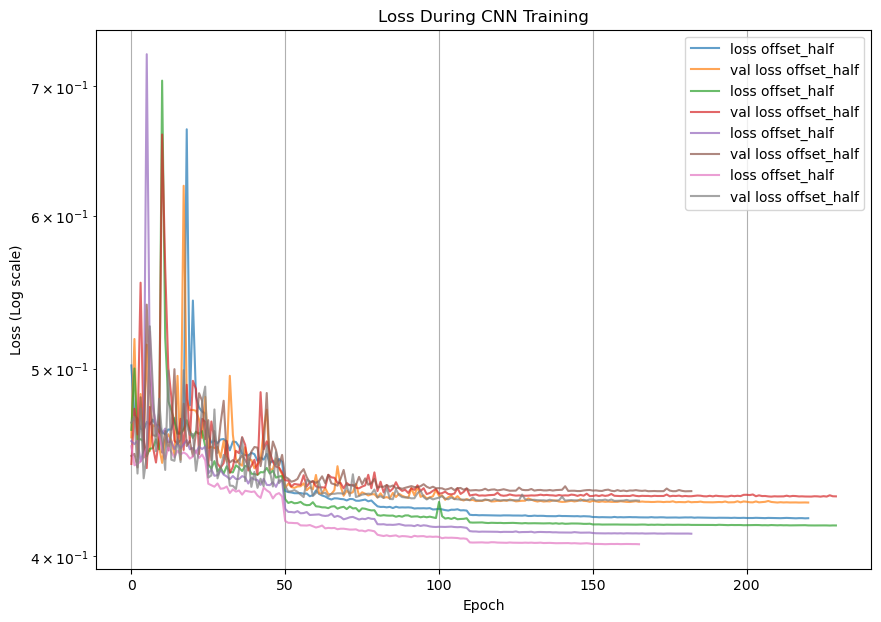

In [72]:
keys = ["offset_half"]
numbers = ["1","2","3","4"]
for key in keys:
    for number in numbers:
        loss = np.load("/home/3155/"+key+"_loss_history"+number+".npy")
        val_loss = np.load("/home/3155/"+key+"_val_loss_history"+number+".npy")
        accuracy = np.load("/home/3155/"+key+"_accuracy_history"+number+".npy")
        val_accuracy = np.load("/home/3155/"+key+"_val_accuracy_history"+number+".npy")
        plt.plot(loss, label='loss '+key, alpha=.7)
        plt.plot(val_loss, label='val loss '+key, alpha=.7)
plt.yscale("log")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss (Log scale)")
plt.title("Loss During CNN Training")
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2.7e-1, 5.5e-1)
# plt.yscale("log")


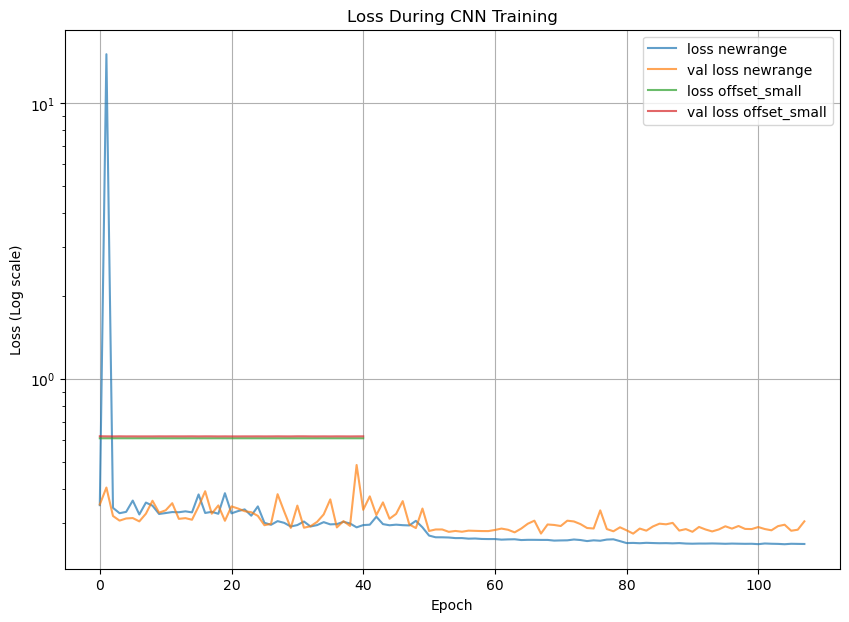

In [6]:
keys = ["newrange", "offset_small"]
for key in keys:
    loss = np.load("/home/3155/"+key+"_loss_history.npy")
    val_loss = np.load("/home/3155/"+key+"_val_loss_history.npy")
    accuracy = np.load("/home/3155/"+key+"_accuracy_history.npy")
    val_accuracy = np.load("/home/3155/"+key+"_val_accuracy_history.npy")
    plt.plot(loss, label='loss '+key, alpha=.7)
    plt.plot(val_loss, label='val loss '+key, alpha=.7)
plt.yscale("log")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss (Log scale)")
plt.title("Loss During CNN Training")
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2.7e-1, 5.5e-1)


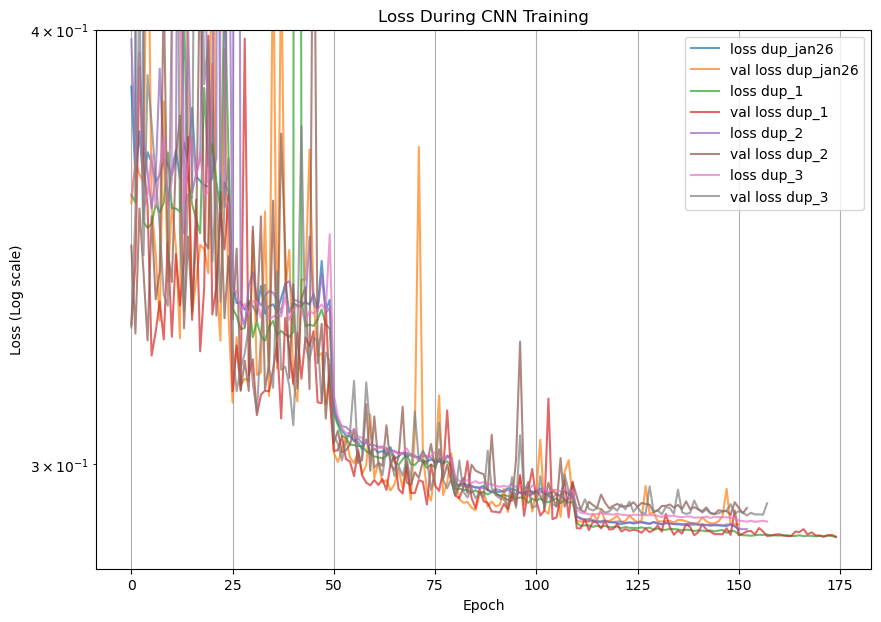

In [20]:
keys = ["dup_jan26", "dup_1", "dup_2", "dup_3"]
for key in keys:
    loss = np.load("/home/3155/"+key+"_loss_history.npy")
    val_loss = np.load("/home/3155/"+key+"_val_loss_history.npy")
    accuracy = np.load("/home/3155/"+key+"_accuracy_history.npy")
    val_accuracy = np.load("/home/3155/"+key+"_val_accuracy_history.npy")
    plt.plot(loss, label='loss '+key, alpha=.7)
    plt.plot(val_loss, label='val loss '+key, alpha=.7)
plt.yscale("log")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss (Log scale)")
plt.title("Loss During CNN Training")
plt.ylim(.28,.4)
plt.grid()

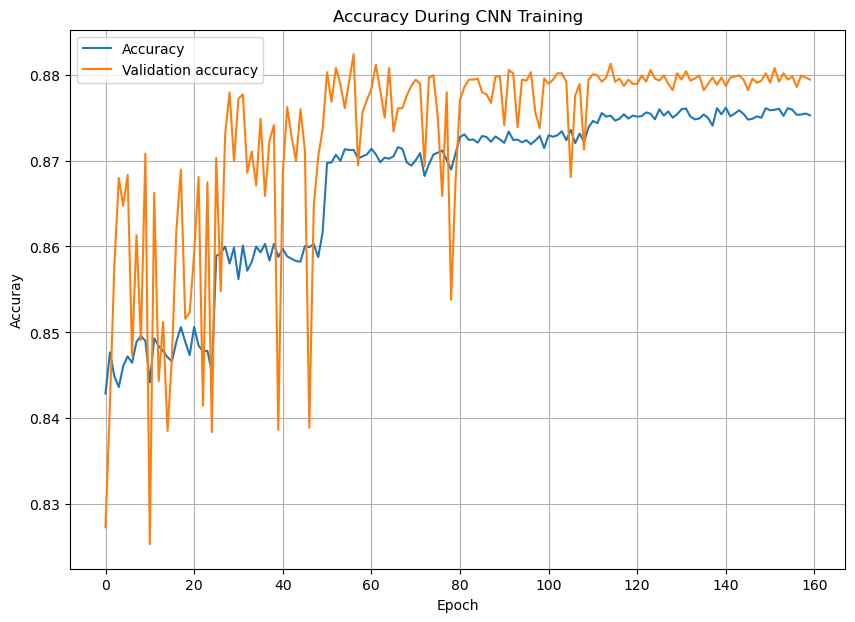

In [41]:
# -- plot the accuracy
plt.plot(accuracy)
plt.plot(val_accuracy)
# plt.plot(np.add(np.array(history.history["accuracy"]),np.array(history.history["val_accuracy"])))
# plt.plot(np.divide(np.array(history.history["val_accuracy"]),np.array(history.history["accuracy"])))
plt.legend(["Accuracy", "Validation accuracy", "ratio val_accuracy/accuracy"])
plt.ylabel("Accuray")
plt.xlabel("Epoch")
plt.title("Accuracy During CNN Training")
# plt.xlim(120,160)
# plt.xlim(50,90)
# plt.ylim(.85, .92)
plt.grid(markevery=5)
# plt.savefig("/home/3155/CNN_best_overfit_longer_200_training_3_outputs/ratio_accuracy_short_early")

In [73]:
keys = ["offset_half"]
models={}
for key in keys:
    models[key] = keras.models.load_model("/home/3155/CNN_"+key)

In [26]:
models

{'newrange': <keras.engine.sequential.Sequential at 0x2b90824e2c10>}

In [24]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 20, 20, 16)        416       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 10, 10, 16)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 10, 10, 32)        4640      
                                                                 
 conv2d_2 (Conv2D)           (None, 10, 10, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 800)               0

In [74]:
label_pred_tes_subset = {}
for key in keys:
    label_pred_tes_subset[key] = models[key].predict(feat_te)

1055/1055 [==============================] - 2s 2ms/step


In [71]:
label_pred_te

array([[2.2402378e-04, 3.4983460e-02, 3.7361637e-01, 6.2395110e-14,
        5.9117609e-01],
       [1.0000000e+00, 1.1800572e-09, 2.1676042e-19, 2.2370184e-18,
        6.8285746e-15],
       [1.0000000e+00, 4.7823560e-16, 0.0000000e+00, 4.6242046e-21,
        7.2842437e-31],
       ...,
       [3.5864315e-36, 1.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00],
       [1.0000000e+00, 3.4108531e-24, 0.0000000e+00, 1.3189598e-24,
        0.0000000e+00],
       [1.0000000e+00, 3.1330099e-08, 1.7517948e-18, 4.5002364e-18,
        1.4526195e-13]], dtype=float32)

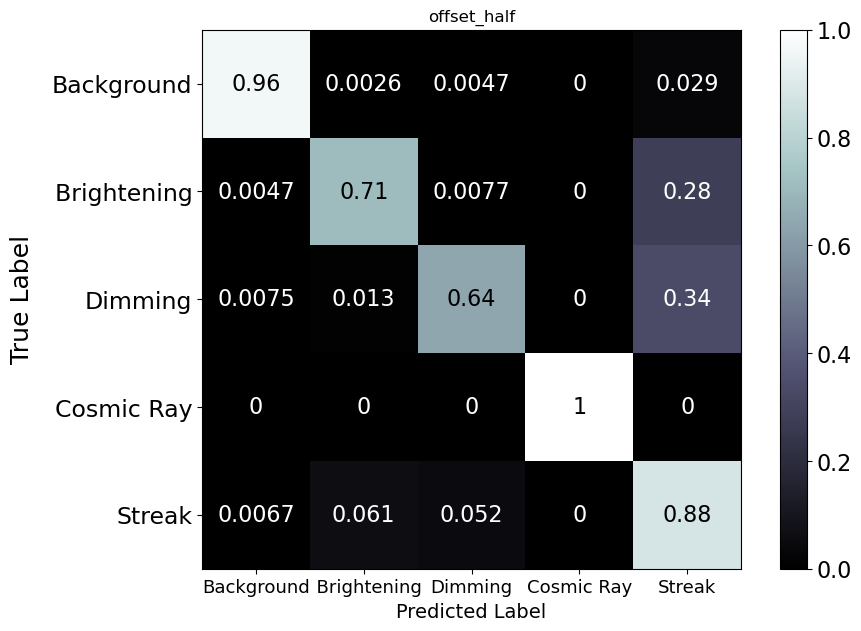

In [75]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_tes_subset[key], axis=1),
    display_labels=["Background", "  Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize="true",
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label
disp.ax_.set_title(key)

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

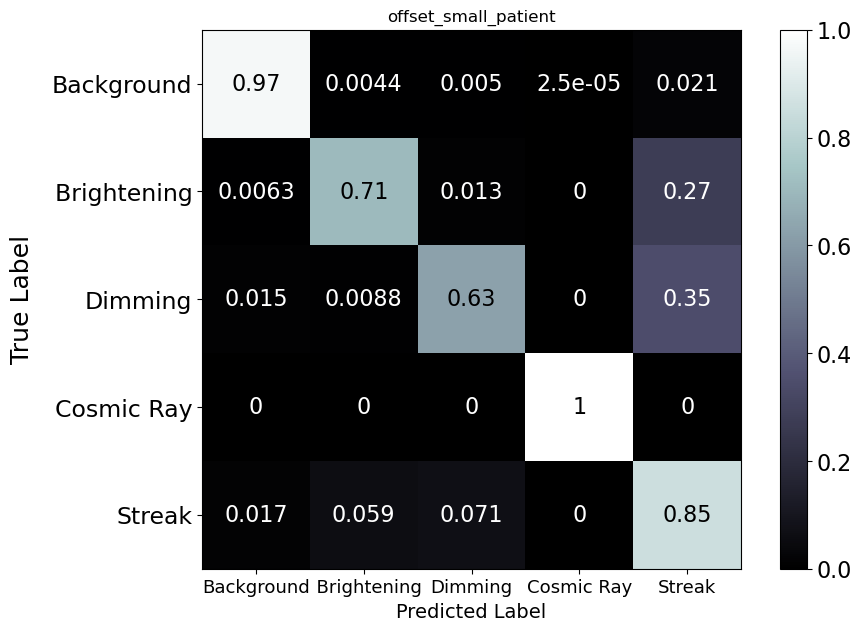

In [53]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_tes_subset[key], axis=1),
    display_labels=["Background", "  Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize="true",
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label
disp.ax_.set_title(key)

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

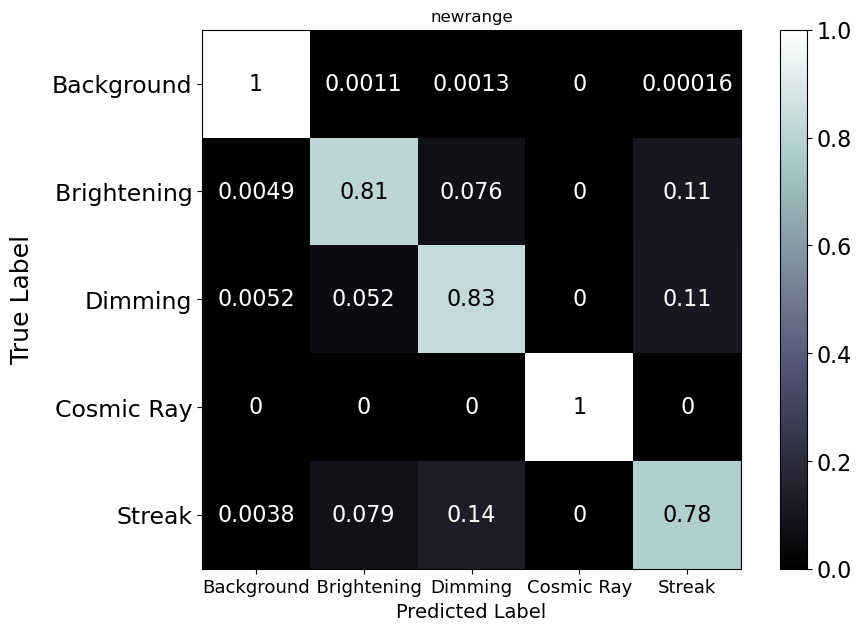

In [30]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_tes[key], axis=1),
    display_labels=["Background", "  Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize="true",
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label
disp.ax_.set_title(key)

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

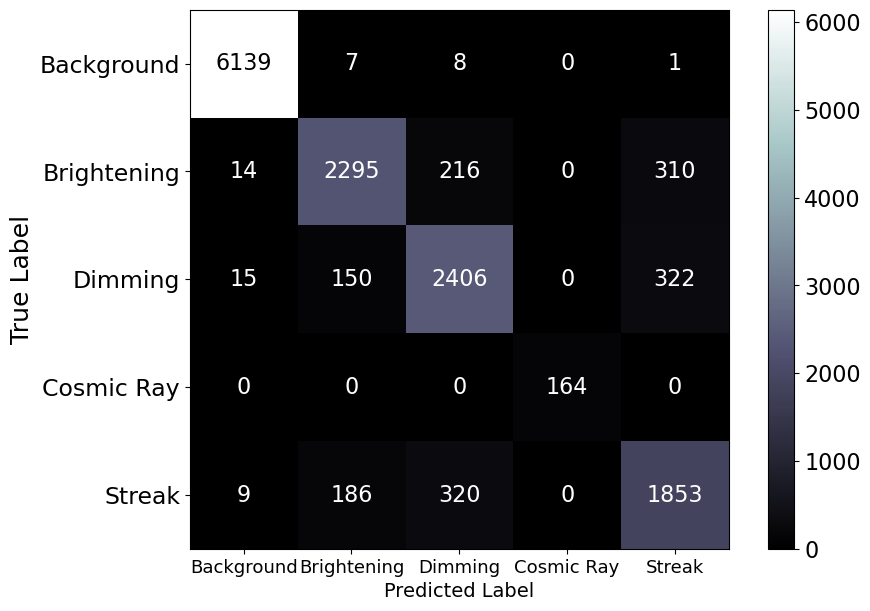

In [31]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_tes[key], axis=1),
    display_labels=["Background", "Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize=None,
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

In [37]:
f1_score(targ_te, np.argmax(label_pred_tes[key], axis=1), average=None)

array([0.99562115, 0.83866253, 0.82354955, 1.        , 0.76349403])

In [17]:
targ_te == 1
np.argmax(label_pred_te, axis=1) == 1
targ_te[np.argmax(label_pred_te, axis=1) == 1]  # targets where label is 1
np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 1] == 1)

393

In [18]:
nlabel_pred_te = label_pred_te[bness_te < 0.95]
plabel_pred_te = label_pred_te[bness_te > 1.05]

In [19]:
label_pred_te[:, 1] > 0.9999

array([False, False, False, ...,  True, False, False])

In [20]:
thr = 0.9999
tp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] == 1)
fp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] != 1)
fn_thr = np.sum(targ_te[label_pred_te[:, 1] < thr] == 1)

In [21]:
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

1.0 0.6953125


In [22]:
tp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 1] == 1)
fp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 1] != 1)
fn = np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 1] == 1)

In [35]:
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print(precision, recall)

0.9550351288056206 0.8384046052631579


In [23]:
tp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 2] == 2)
fp = np.sum(targ_te[np.argmax(label_pred_te, axis=1) == 2] != 2)
fn = np.sum(targ_te[np.argmax(label_pred_te, axis=1) != 2] == 2)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print(precision, recall)

0.8152115693626139 0.6284062758051198


In [24]:
thr = 0.9999
tp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] == 2)
fp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] != 2)
fn_thr = np.sum(targ_te[label_pred_te[:, 2] < thr] == 2)
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

0.9958071278825996 0.19611890999174236


In [92]:
# threshes = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.995, 0.9999]
threshes = np.linspace(0.1, 0.9999, 50)

In [96]:
len(targ_te)

33729

In [97]:
len()

33729

In [98]:
label_pred_te = label_pred_tes_subset[key]
prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(targ_te[label_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(targ_te[label_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(targ_te[label_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(targ_te[label_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

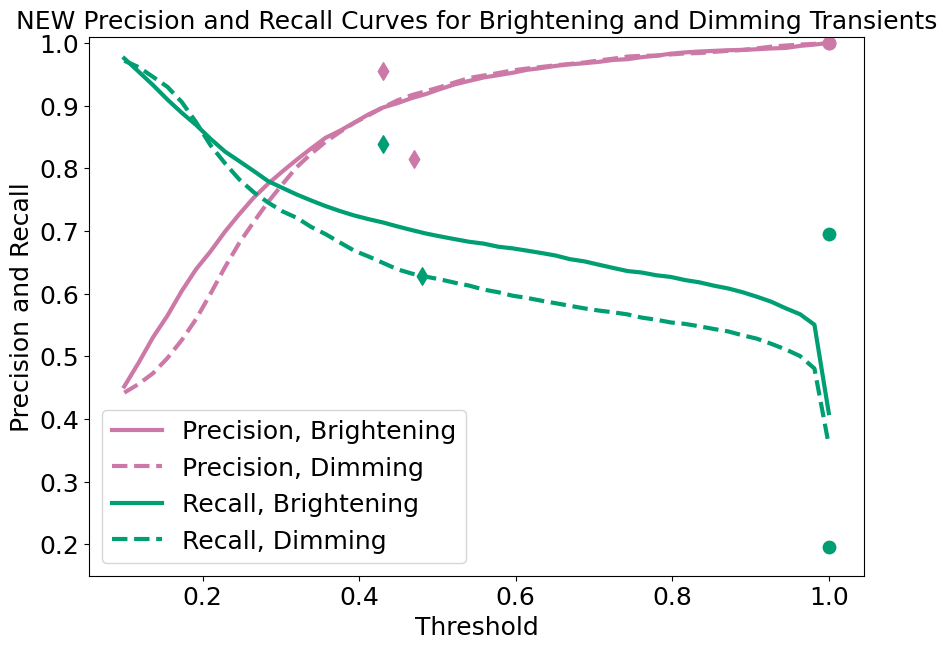

In [99]:
plt.plot(threshes, prec_br, label="Precision, Brightening", linewidth=3, c="#cc79a7")
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(threshes, rec_br, label="Recall, Brightening", linewidth=3, c="#009e73")
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
plt.scatter(0.43, 0.9550351288056206, s=80, marker="d", c="#cc79a7")
plt.scatter(0.47, 0.8152115693626139, s=80, marker="d", c="#cc79a7")
plt.scatter(0.43, 0.8384046052631579, s=80, marker="d", c="#009e73")

plt.scatter(0.48, 0.6284062758051198, s=80, marker="d", c="#009e73")

plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 0.695, s=80, marker="o", c="#009e73")
plt.scatter(0.9999, 0.196, s=80, marker="o", c="#009e73")

plt.legend(fontsize=18)
plt.title(
    "NEW Precision and Recall Curves for Brightening and Dimming Transients", fontsize=18
)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

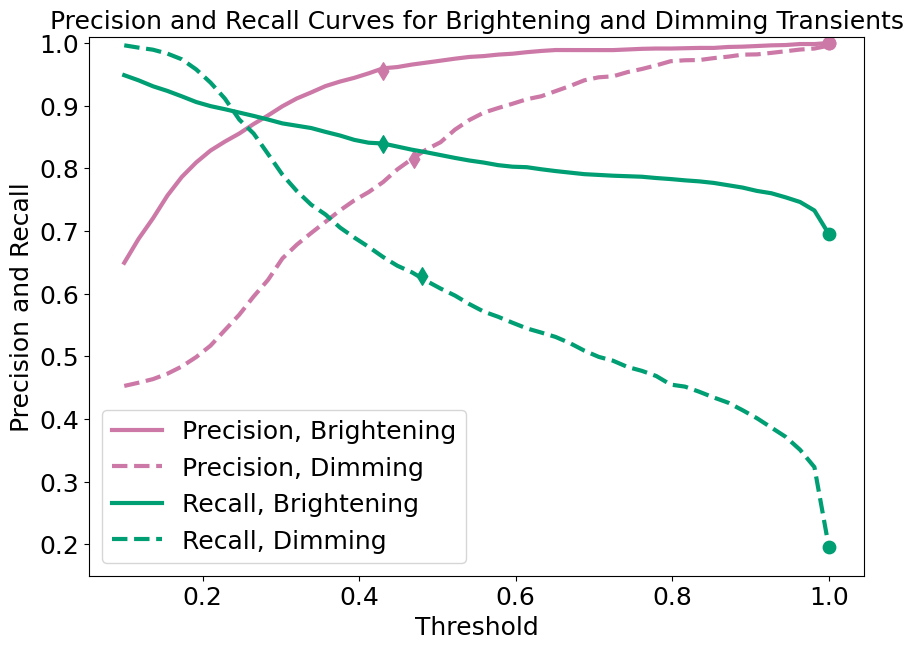

In [50]:
plt.plot(threshes, prec_br, label="Precision, Brightening", linewidth=3, c="#cc79a7")
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(threshes, rec_br, label="Recall, Brightening", linewidth=3, c="#009e73")
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
plt.scatter(0.43, 0.9550351288056206, s=80, marker="d", c="#cc79a7")
plt.scatter(0.47, 0.8152115693626139, s=80, marker="d", c="#cc79a7")
plt.scatter(0.43, 0.8384046052631579, s=80, marker="d", c="#009e73")

plt.scatter(0.48, 0.6284062758051198, s=80, marker="d", c="#009e73")

plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 1, s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, 0.695, s=80, marker="o", c="#009e73")
plt.scatter(0.9999, 0.196, s=80, marker="o", c="#009e73")

plt.legend(fontsize=18)
plt.title(
    "Precision and Recall Curves for Brightening and Dimming Transients", fontsize=18
)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [97]:
targ_te[all(0 < bness_te < 0.95)]

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [33]:
nlabel_pred_te = label_pred_te[bness_te < 0.9]
plabel_pred_te = label_pred_te[bness_te > 1.03]
ntarg_te = targ_te[bness_te < 0.9]
ptarg_te = targ_te[bness_te > 1.03]

prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

In [117]:
# threshes = [.1,.2,.3,.4,.5,.6,.7,.8,.9, .99, .9999]

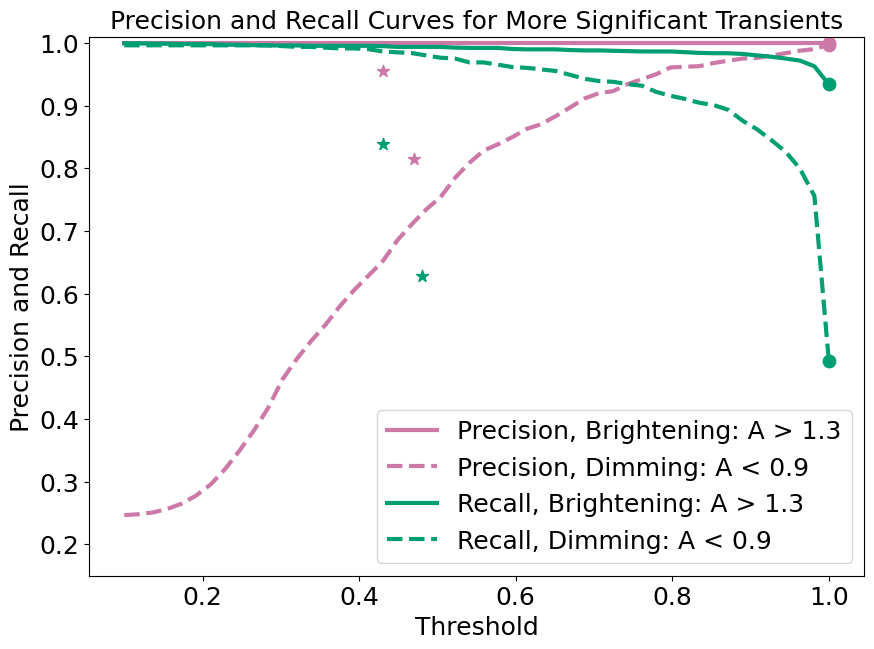

In [21]:
plt.plot(
    threshes, prec_br, label="Precision, Brightening: A > 1.3", linewidth=3, c="#cc79a7"
)
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(
    threshes, rec_br, label="Recall, Brightening: A > 1.3", linewidth=3, c="#009e73"
)
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
# plt.scatter(.43,  0.9550351288056206,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.47,  0.8152115693626139,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.43,  0.8384046052631579,  s=80, marker='d', c='#009e73')

plt.scatter(0.9999, prec_br[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, prec_dim[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, rec_br[-1], s=80, marker="o", c="#009e73")
plt.scatter(0.9999, rec_dim[-1], s=80, marker="o", c="#009e73")

plt.legend(fontsize=18)
plt.title("Precision and Recall Curves for More Significant Transients", fontsize=18)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [ ]:
#adding oct 2025

In [19]:
nlabel_pred_te = label_pred_te[bness_te < 0.9]
plabel_pred_te = label_pred_te[bness_te > 1.1]
ntarg_te = targ_te[bness_te < 0.9]
ptarg_te = targ_te[bness_te > 1.1]

prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

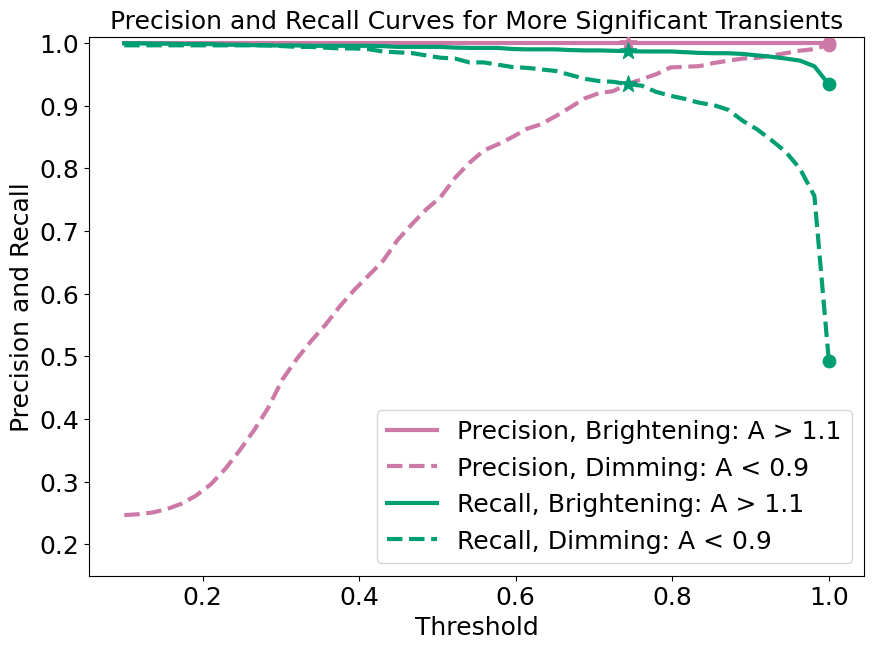

In [61]:
plt.plot(
    threshes, prec_br, label="Precision, Brightening: A > 1.1", linewidth=3, c="#cc79a7"
)
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(
    threshes, rec_br, label="Recall, Brightening: A > 1.1", linewidth=3, c="#009e73"
)
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming: A < 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
# plt.scatter(.43,  0.9550351288056206,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.47,  0.8152115693626139,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.43,  0.8384046052631579,  s=80, marker='d', c='#009e73')

plt.scatter(0.9999, prec_br[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, prec_dim[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, rec_br[-1], s=80, marker="o", c="#009e73")
plt.scatter(0.9999, rec_dim[-1], s=80, marker="o", c="#009e73")

plt.scatter(0.743, 1.0, s=150, marker="*", c="#cc79a7", zorder=10)
plt.scatter(0.743, 0.9870349492671928, s=150, marker="*", c="#009e73", zorder=10)
# plt.scatter(0.743,0.9343246592317225, s=80, marker="*", c="#009e73", zorder=10)

plt.scatter(0.743, 0.9343246592317225, s=150, marker="*", c="#009e73", zorder=10)

plt.legend(fontsize=18)
plt.title("Precision and Recall Curves for More Significant Transients", fontsize=18)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [28]:
nlabel_pred_te = label_pred_te[bness_te <= 0.9]
plabel_pred_te = label_pred_te[bness_te >= 1.1]
ntarg_te = targ_te[bness_te <= 0.9]
ptarg_te = targ_te[bness_te >= 1.1]

prec_br = []
prec_dim = []
rec_br = []
rec_dim = []
for thr in threshes:
    tp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
    fp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
    fn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_br.append(precision_thr)
    rec_br.append(recall_thr)
    tp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
    fp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
    fn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)
    precision_thr = tp_thr / (tp_thr + fp_thr)
    recall_thr = tp_thr / (tp_thr + fn_thr)
    prec_dim.append(precision_thr)
    rec_dim.append(recall_thr)

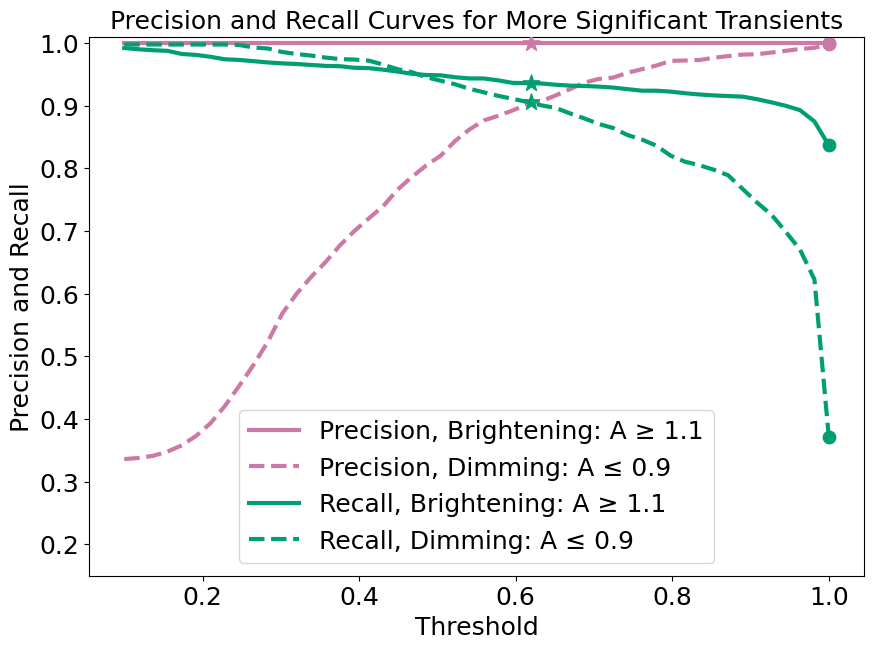

In [54]:
plt.plot(
    threshes, prec_br, label="Precision, Brightening: A ≥ 1.1", linewidth=3, c="#cc79a7"
)
plt.plot(
    threshes,
    prec_dim,
    label="Precision, Dimming: A ≤ 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#cc79a7",
)
plt.plot(
    threshes, rec_br, label="Recall, Brightening: A ≥ 1.1", linewidth=3, c="#009e73"
)
plt.plot(
    threshes,
    rec_dim,
    label="Recall, Dimming: A ≤ 0.9",
    linewidth=3,
    linestyle="dashed",
    c="#009e73",
)
# plt.plot(threshes, np.full( len(threshes), 0.9550351288056206), label="Precision Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8384046052631579), label="Recall Brightening Max")
# plt.plot(threshes, np.full( len(threshes), 0.8152115693626139), label="Precision Dimming Max")
# plt.plot(threshes, np.full( len(threshes), 0.6284062758051198), label="Recall Dimming Max")
# plt.scatter(.43,  0.9550351288056206,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.47,  0.8152115693626139,  s=80, marker='d', c='#cc79a7')
# plt.scatter(.43,  0.8384046052631579,  s=80, marker='d', c='#009e73')

plt.scatter(0.9999, prec_br[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, prec_dim[-1], s=80, marker="o", c="#cc79a7")
plt.scatter(0.9999, rec_br[-1], s=80, marker="o", c="#009e73")
plt.scatter(0.9999, rec_dim[-1], s=80, marker="o", c="#009e73")

plt.scatter(0.62, 1.0, s=150, marker="*", c="#cc79a7", zorder=10)
plt.scatter(0.62, 0.9052969502407705, s=150, marker="*", c="#009e73", zorder=10)
# plt.scatter(0.743,0.9343246592317225, s=80, marker="*", c="#009e73", zorder=10)
plt.scatter(0.62, 0.9359038557836755, s=150, marker="*", c="#009e73", zorder=10)

plt.legend(fontsize=18)
plt.title("Precision and Recall Curves for More Significant Transients", fontsize=18)
plt.xlabel("Threshold", fontsize=18)
plt.ylabel("Precision and Recall", fontsize=18)
plt.ylim(0.15, 1.01)
plt.tick_params(axis="both", labelsize=18)

In [34]:


nlabel_pred_te = label_pred_te[bness_te <= 0.9]
plabel_pred_te = label_pred_te[bness_te >= 1.1]
ntarg_te = targ_te[bness_te <= 0.9]
ptarg_te = targ_te[bness_te >= 1.1]

In [63]:
thr = 0.62

In [47]:



tp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
fp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
fn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

1.0 0.9359038557836755


In [37]:
print(tp_thr, fp_thr, fn_thr)

0 1 0


In [41]:
plabel_pred_te[:, 2]

array([0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 2.5579392e-37,
       1.0280589e-03, 0.0000000e+00], dtype=float32)

In [64]:
tp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
fp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
fn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)
precision_thr = tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

0.9031224979983987 0.9052969502407705


In [63]:
print(tp_thr, fp_thr, fn_thr)

754 53 53


In [65]:
#getting for both pos and neg
ptp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
pfp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
pfn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)

ntp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
nfp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
nfn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)

tp_thr = ptp_thr + ntp_thr
fp_thr = pfp_thr + nfp_thr
fn_thr = pfn_thr + nfn_thr

precision_thr =tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

0.9611930724823605 0.9241443108233117


In [60]:
thr=.60

In [33]:
#again for inclusive of 10 percent
nlabel_pred_te = label_pred_te[bness_te <= 0.9]
plabel_pred_te = label_pred_te[bness_te >= 1.1]
ntarg_te = targ_te[bness_te <= 0.9]
ptarg_te = targ_te[bness_te >= 1.1]


#getting for both pos and neg
ptp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] == 1)
pfp_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] > thr] != 1)
pfn_thr = np.sum(ptarg_te[plabel_pred_te[:, 1] < thr] == 1)

ntp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] == 2)
nfp_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] > thr] != 2)
nfn_thr = np.sum(ntarg_te[nlabel_pred_te[:, 2] < thr] == 2)

tp_thr = ptp_thr + ntp_thr
fp_thr = pfp_thr + nfp_thr
fn_thr = pfn_thr + nfn_thr

precision_thr =tp_thr / (tp_thr + fp_thr)
recall_thr = tp_thr / (tp_thr + fn_thr)
print(precision_thr, recall_thr)

0.9611930724823605 0.9241443108233117


In [47]:
np.shape(all_neg_stamps_info)

(9715, 2)

In [43]:
np.shape(np.zeros((np.shape(all_bg_stamps)[0], 2)))

(24382, 2)

In [19]:
np.shape(targ_te)

(13532,)

In [35]:
feat_te_info[:, 0]

NameError: name 'feat_te_info' is not defined

In [125]:
np.unique(all_pos_stamps_info[:, 0])

array([ 1.01,  1.05,  1.1 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,
        8.  , 10.  ])

In [ ]:
# okay so feat_te_info contains the information

In [65]:
all_pos_stamps_info[1]

array([10.,  8.])

In [ ]:
# brightness, length

In [39]:
our_feat_te = feat_te[bness_te > 0]

In [40]:
our_bness_te = bness_te[bness_te > 0]

In [41]:
our_lens_te = lens_te[bness_te > 0]

In [42]:
our_bness_te

array([1.15, 0.8 , 0.6 , ..., 0.9 , 0.6 , 0.6 ])

In [44]:
label_pred_te = label_pred_tes[key]

In [45]:
our_pred_te_max = np.argmax(label_pred_te[bness_te > 0], axis=1)

In [46]:
our_targ_te = targ_te[bness_te > 0]

In [47]:
np.shape(our_targ_te)

(5728,)

In [37]:
# info = np.load('/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans/info/ztf_20221020138241_000686_zi_c08_x_0024._4_stamps_info.npy')

In [38]:
our_feat_te_p8 = our_feat_te[our_outs_te == 0.8]

NameError: name 'our_outs_te' is not defined

In [39]:
label_pred_te

array([[2.2402358e-04, 3.4983490e-02, 3.7361595e-01, 6.2395503e-14,
        5.9117645e-01],
       [1.0000000e+00, 1.1800572e-09, 2.1675049e-19, 2.2370184e-18,
        6.8284705e-15],
       [1.0000000e+00, 4.7823925e-16, 0.0000000e+00, 4.6241690e-21,
        7.2842992e-31],
       ...,
       [3.5864315e-36, 1.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00],
       [1.0000000e+00, 3.4109052e-24, 0.0000000e+00, 1.3189598e-24,
        0.0000000e+00],
       [1.0000000e+00, 3.1329623e-08, 1.7516877e-18, 4.5002364e-18,
        1.4525752e-13]], dtype=float32)

In [43]:
trues = []
fails = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_label_pred_te_max[i]:
        trues.append(our_feat_te_info[i])
    else:
        fails.append(our_feat_te_info[i])
fails = np.array(fails)
trues = np.array(trues)

NameError: name 'our_label_pred_te_max' is not defined

In [42]:
our_pred_te_max[:10]

array([4, 4, 2, 2, 4, 1, 4, 1, 1, 1])

In [48]:
trues = []
fails = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_pred_te_max[i]:
        trues.append([our_bness_te[i], our_lens_te[i]])
    else:
        fails.append([our_bness_te[i], our_lens_te[i]])
fails = np.array(fails)
trues = np.array(trues)

In [34]:
our_feat_te_pos = feat_te[bness_te > 1]
our_feat_te_pos = our_feat_te[bness_te < 1.06]

our_bness_te_pos = outs_te[bness_te > 0]
our_bness_te_pos = our_bness_te_pos[bness_te > 0]

our_targ_te = targ_te[bness_te > 0]

our_pred_te_max = np.argmax(label_pred_te[bness_te > 0], axis=1)

NameError: name 'our_feat_te' is not defined

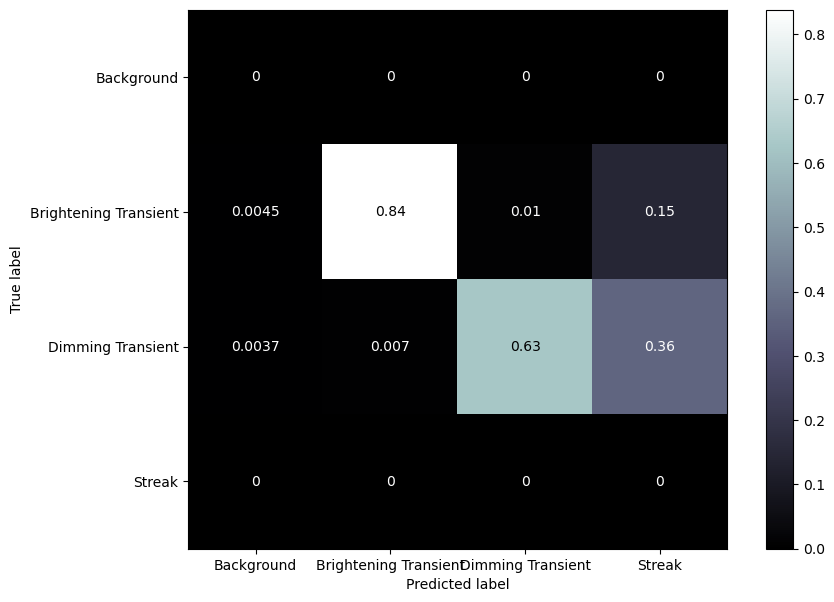

In [61]:
ConfusionMatrixDisplay.from_predictions(
    our_targ_te,
    our_pred_te_max,
    display_labels=[
        "Background",
        "Brightening Transient",
        "Dimming Transient",
        "Streak",
    ],  # "Cosmic Ray",
    cmap="bone",
    normalize="true",
)

In [292]:
len(trues)

3566

In [293]:
len(fails)

1288

In [34]:
import seaborn as sns

In [30]:
np.unique(our_feat_te_info[:, 1])

NameError: name 'our_feat_te_info' is not defined

In [47]:
trues

[]

In [39]:
np.unique(bness_te)

array([0.000e+00, 1.000e+00, 2.000e+00, 1.000e+01, 1.200e+01, 1.500e+01,
       1.600e+01, 1.700e+01, 1.800e+01, 2.000e+01, 2.100e+01, 2.200e+01,
       2.300e+01, 2.600e+01, 2.800e+01, 2.900e+01, 3.100e+01, 3.300e+01,
       3.400e+01, 3.600e+01, 3.700e+01, 3.800e+01, 3.900e+01, 4.300e+01,
       4.400e+01, 4.500e+01, 4.600e+01, 4.700e+01, 5.200e+01, 5.300e+01,
       5.400e+01, 5.500e+01, 5.600e+01, 5.900e+01, 6.000e+01, 6.100e+01,
       6.200e+01, 6.300e+01, 6.500e+01, 6.600e+01, 6.800e+01, 6.900e+01,
       7.200e+01, 7.400e+01, 7.600e+01, 7.700e+01, 7.900e+01, 8.000e+01,
       8.100e+01, 8.300e+01, 8.400e+01, 8.500e+01, 8.700e+01, 9.100e+01,
       9.200e+01, 9.300e+01, 9.400e+01, 9.500e+01, 9.600e+01, 9.700e+01,
       9.800e+01, 9.900e+01, 1.010e+02, 1.020e+02, 1.040e+02, 1.060e+02,
       1.070e+02, 1.110e+02, 1.130e+02, 1.140e+02, 1.180e+02, 1.200e+02,
       1.210e+02, 1.220e+02, 1.240e+02, 1.250e+02, 1.300e+02, 1.310e+02,
       1.330e+02, 1.350e+02, 1.390e+02, 1.400e+02, 

In [54]:
length_values = np.unique(lens_te[lens_te>0])

In [55]:
our_feat_te = feat_te[bness_te > 0]

In [56]:
our_bness_te = bness_te[bness_te > 0]

In [57]:
our_lens_te = lens_te[bness_te > 0]

In [58]:
our_bness_te

array([1.1  , 0.6  , 2.   , ..., 0.8  , 1.15 , 0.995])

In [59]:
label_pred_te = label_pred_tes_subset[key]

In [60]:
our_pred_te_max = np.argmax(label_pred_te[bness_te > 0], axis=1)

In [61]:
our_targ_te = targ_te[bness_te > 0]

In [62]:
trues = []
fails = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_pred_te_max[i]:
        trues.append([our_bness_te[i], our_lens_te[i]])
    else:
        fails.append([our_bness_te[i], our_lens_te[i]])
fails = np.array(fails)
trues = np.array(trues)

In [63]:
fails

array([[1.01 , 4.   ],
       [0.99 , 6.   ],
       [1.01 , 8.   ],
       ...,
       [0.95 , 4.   ],
       [0.8  , 7.   ],
       [0.995, 9.   ]])

50.0

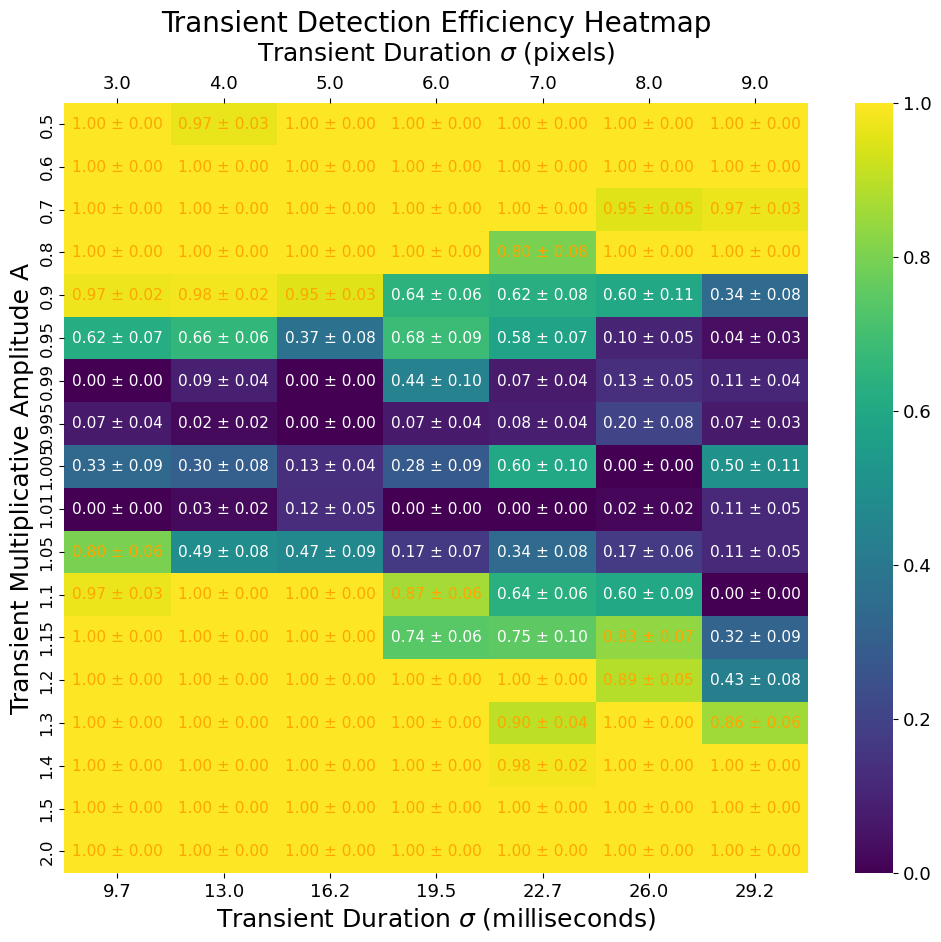

In [68]:
# Given nonlinear brightness values
brightness_values = np.unique(our_bness_te)
length_values = np.unique(our_lens_te)

# # Given nonlinear brightness and length values
# brightness_values = np.array([0.8, 0.9, 0.99, 1.01, 1.1, 2, 5, 10])
# length_values = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Example length values

# Create bins for brightness and length
brightness_bins = np.concatenate(
    [
        [brightness_values[0] - 0.1],
        (brightness_values[:-1] + brightness_values[1:]) / 2,
        [brightness_values[-1] + 0.1],
    ]
)

length_bins = np.concatenate(
    [
        [length_values[0] - 0.5],
        (length_values[:-1] + length_values[1:]) / 2,
        [length_values[-1] + 0.5],
    ]
)

# Example data: Replace these with your actual data
correct_detections = trues  # Array of correctly detected (brightness, length)
incorrect_detections = fails  # Array of incorrectly detected (brightness, length)

# Create 2D histogram for correct and total detections
correct_hist, xedges, yedges = np.histogram2d(
    correct_detections[:, 0],
    correct_detections[:, 1],
    bins=[brightness_bins, length_bins],
)

total_hist, _, _ = np.histogram2d(
    np.vstack((correct_detections, incorrect_detections))[:, 0],
    np.vstack((correct_detections, incorrect_detections))[:, 1],
    bins=[brightness_bins, length_bins],
)

# Calculate efficiency
efficiency = correct_hist / total_hist

# Calculate error (using Poisson approximation)
error = np.sqrt(efficiency * (1 - efficiency) / total_hist)

# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}" #{total_hist[i,j]}"#
            # Add the text annotation in the center of each bin
            if efficiency[i, j]<.8:
                color="white"
            else:
                color='orange'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

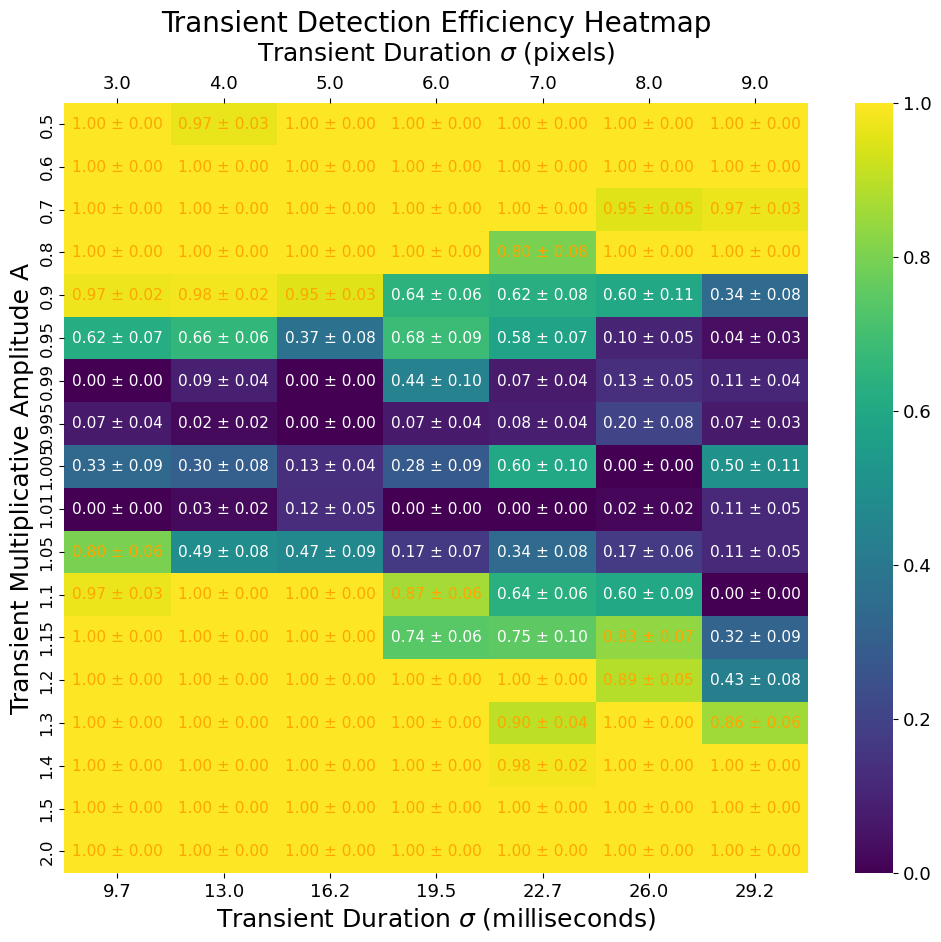

In [65]:
# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin
            if efficiency[i, j]<.8:
                color="white"
            else:
                color='orange'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

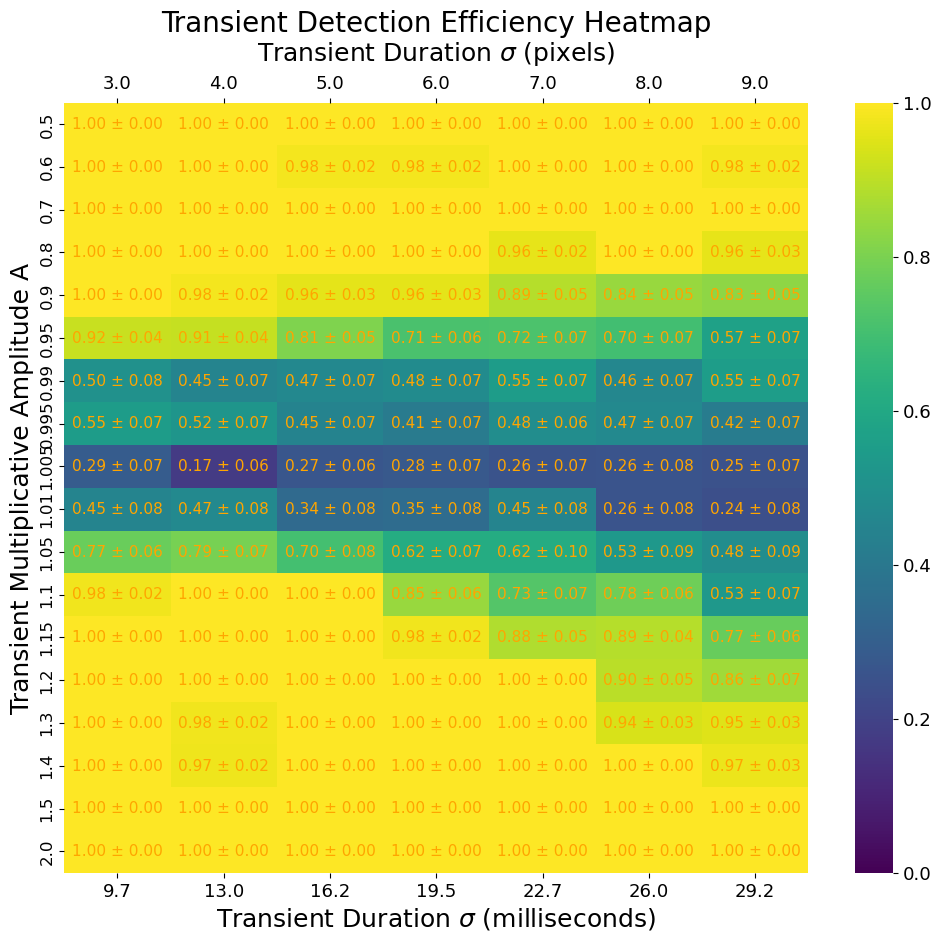

In [62]:
# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin

            color='orange'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

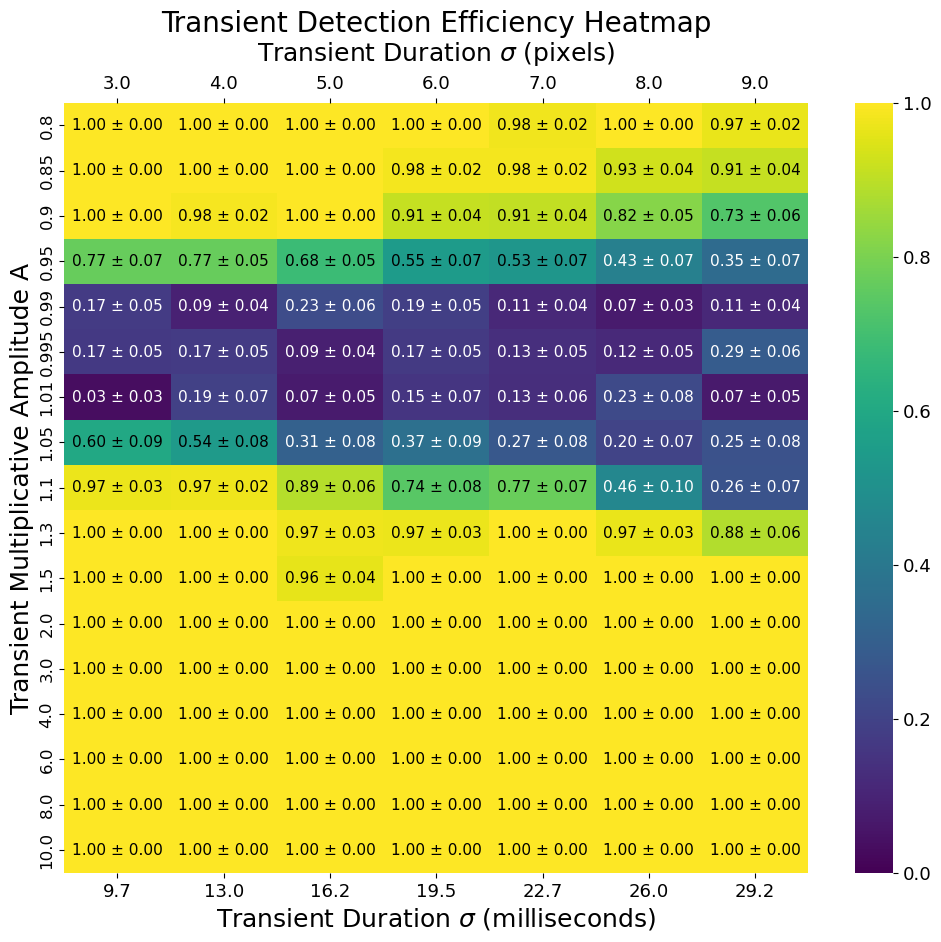

In [58]:
# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin
            if efficiency[i, j]<.5:
                color="white"
            else:
                color='black'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

In [56]:
feat_tr2, feat_te2, bness_tr2, bness_te2, lens_tr2, lens_te2, targ_tr2, targ_te2 = train_test_split(feat, bness, lens, targ, random_state=302)


In [61]:
np.sum(lens_te2.reshape(lens_te.shape)-lens_te)

0.0

NameError: name 'colors' is not defined

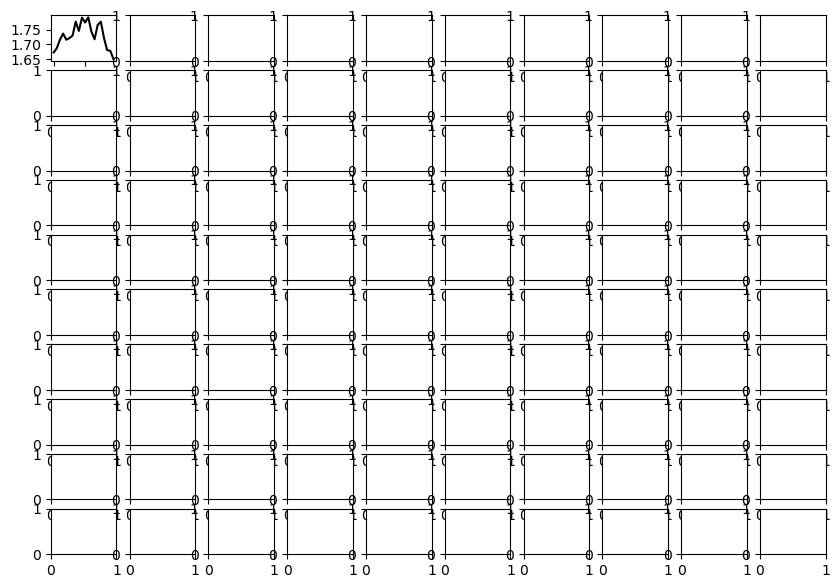

In [55]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].set_facecolor(colors[our_pred_te_max[i * 10 + h]])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

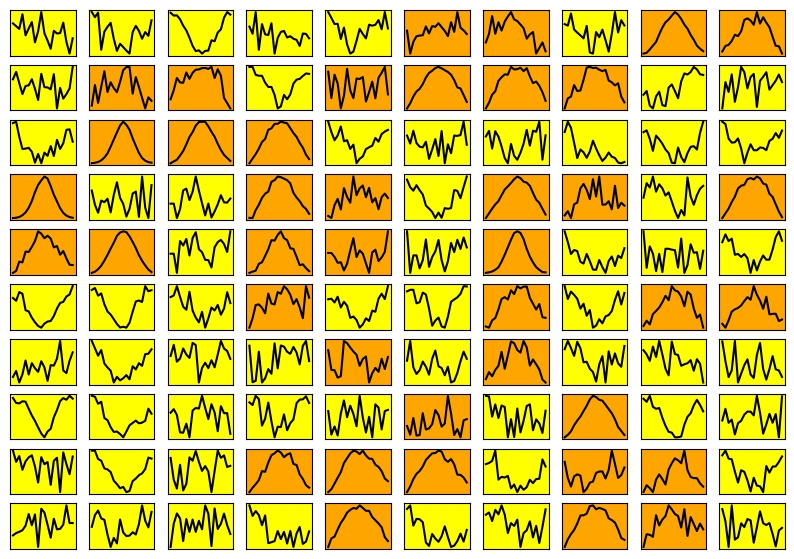

In [250]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].set_facecolor(colors[our_targ_te[i * 10 + h]])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

In [89]:
our_feat_te_info[0, 0]

0.99

In [178]:
colors2 = [0, 1, 2, "red", "orange", "yellow", "green", "blue", "purple", "violet"]

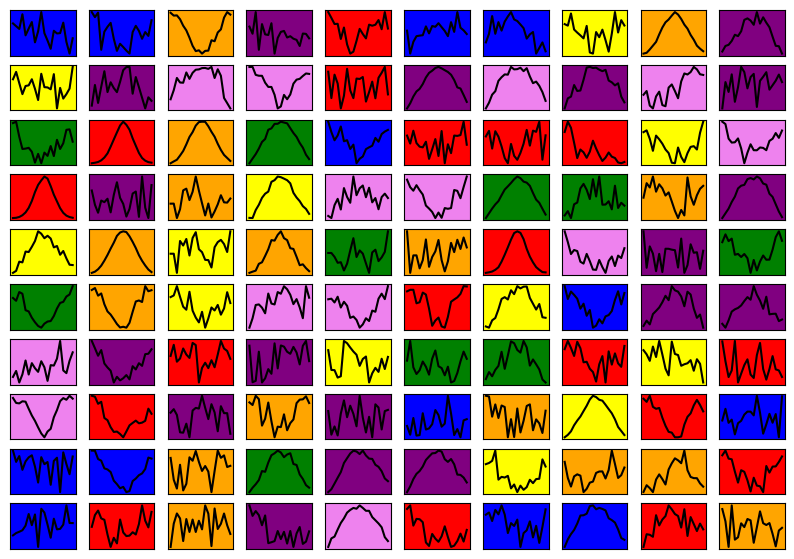

In [251]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(colors2[int(our_feat_te_info[i * 10 + h, 1])])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

In [ ]:
# i'm not convinced the lengths are working right
# ...eh maybe they are. purple/pink should be

In [124]:
x = np.linspace(0.0, 1.0, 1001)
rgb = mpl.colormaps["viridis"](x)[np.newaxis, :, :3]

In [107]:
np.max(100 * (our_feat_te_info[:, 0]))

1000.0

In [120]:
np.shape(rgb)

(1, 1000, 3)

In [113]:
rgb[int(100 * (our_feat_te_info[i * 10 + h, 0]))]

IndexError: index 99 is out of bounds for axis 0 with size 1

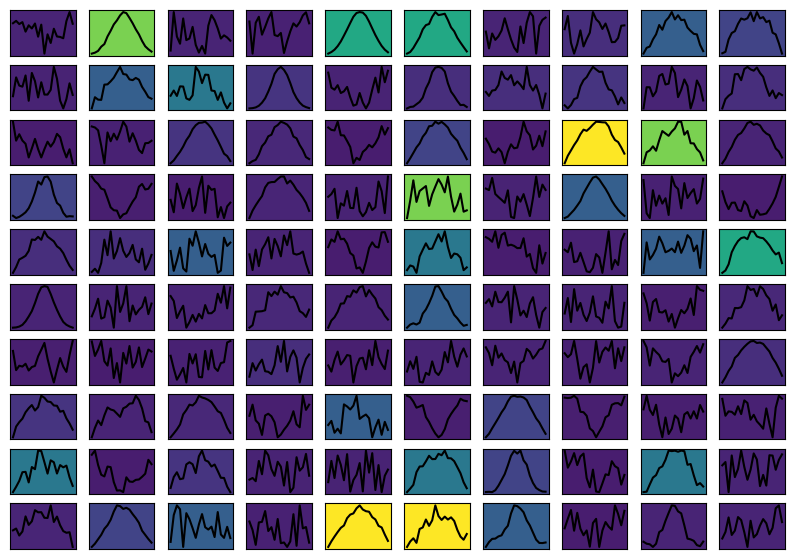

In [125]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(rgb[0, int(100 * (our_feat_te_info[i * 10 + h, 0]))])
        # ax[i, h].axis("off")
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

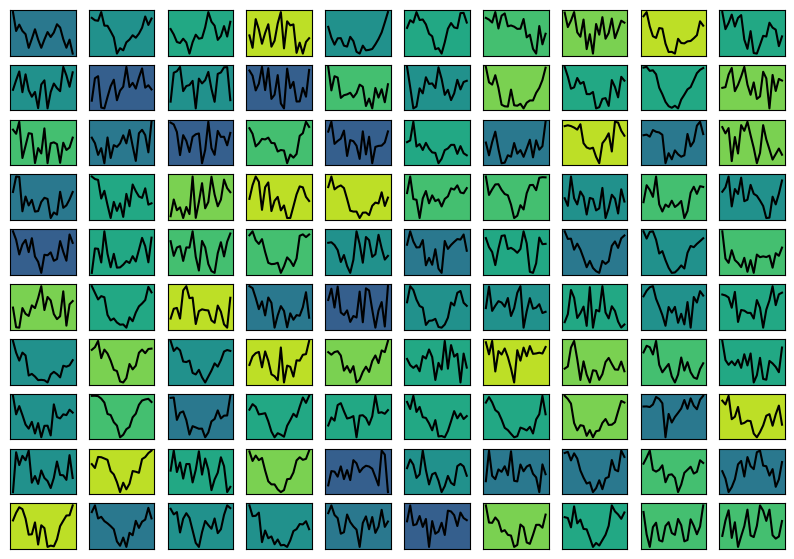

In [148]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(our_feat_te_p8[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        ax[i, h].set_facecolor(rgb[0, int(100 * (our_feat_te_info_p8[i * 10 + h, 1]))])
        # ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_p8[i*10 + h]])
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

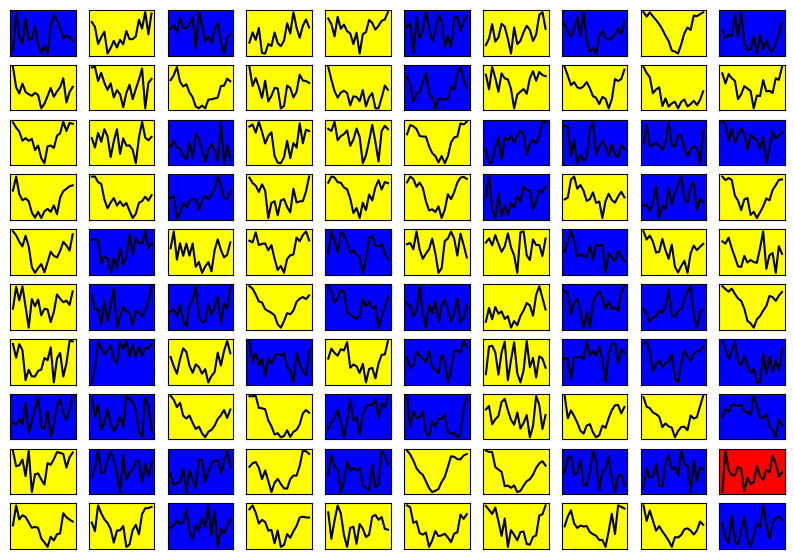

In [40]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.mean(our_feat_te_995[i * 10 + h], axis=1), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        # ax[i, h].axis("off")
        ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i * 10 + h]])
        ax[i, h].set_xticks([])
        ax[i, h].set_yticks([])
fig.show()

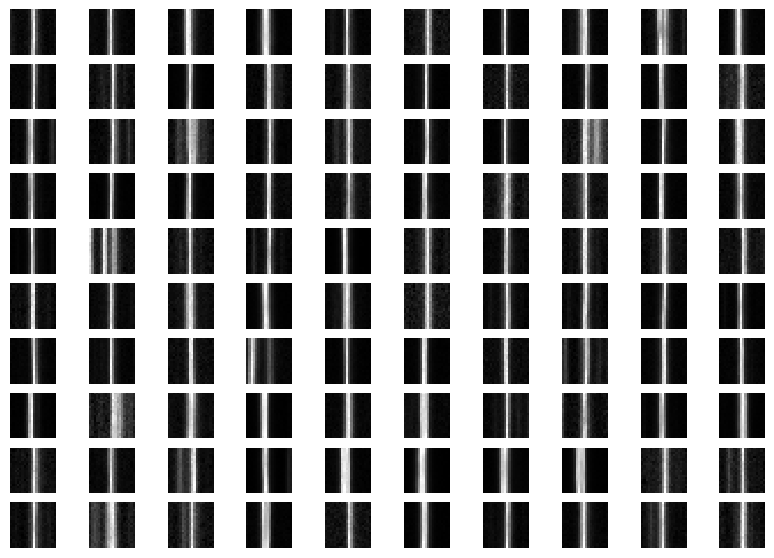

In [36]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        # ax[i, h].plot(np.sum(our_feat_te_995[i*10 + h], axis=1), "black")
        ax[i, h].imshow(our_feat_te_995[i * 10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i*10 + h]])
        # ax[i, h].set_xticks([])
        # ax[i, h].set_yticks([])
fig.show()

In [41]:
feat_te_info[:, 0]

array([0.99, 0.  , 0.  , ..., 4.  , 0.  , 0.  ])

In [45]:
unique, counts = np.unique(feat_te_info[:, 0], return_counts=True)

In [ ]:
unique

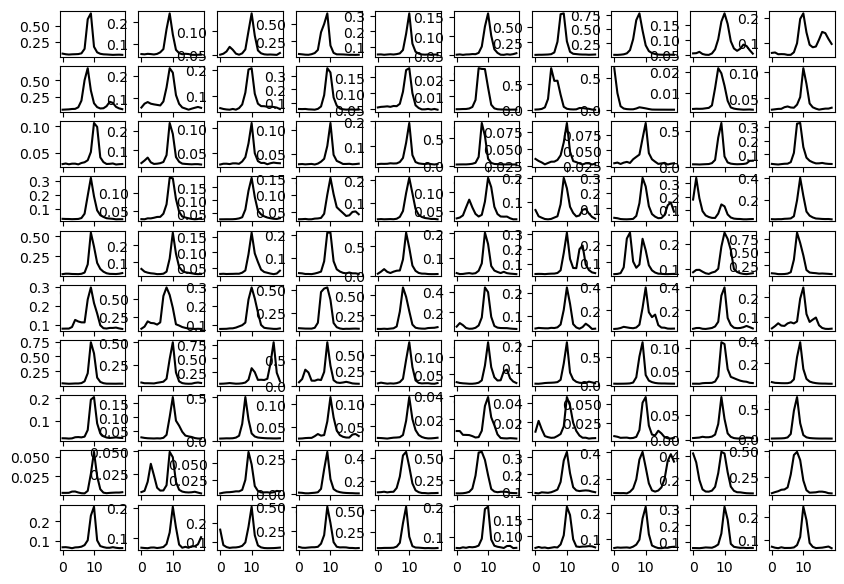

In [74]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.mean(all_streak_stamps[i * 10 + h], axis=0), "black")
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        # ax[i, h].set_facecolor((our_feat_te_info_p8[i*10 + h,1]/10, .5, .5))
        # ax[i, h].set_facecolor(rgb[0,int(100*(our_feat_te_info_p8[i*10 + h,1]))])
        # ax[i, h].axis("off")
        # ax[i, h].set_facecolor(colors[our_label_pred_te_max_995[i*10 + h]])
        # ax[i, h].set_xticks([])
        # ax[i, h].set_yticks([])
fig.show()

[4, 4]


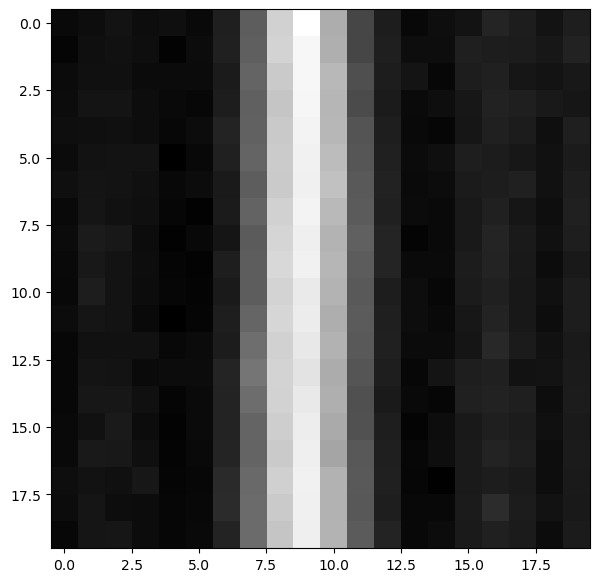

stamp info:  (0.99, 3)
[4, 4]


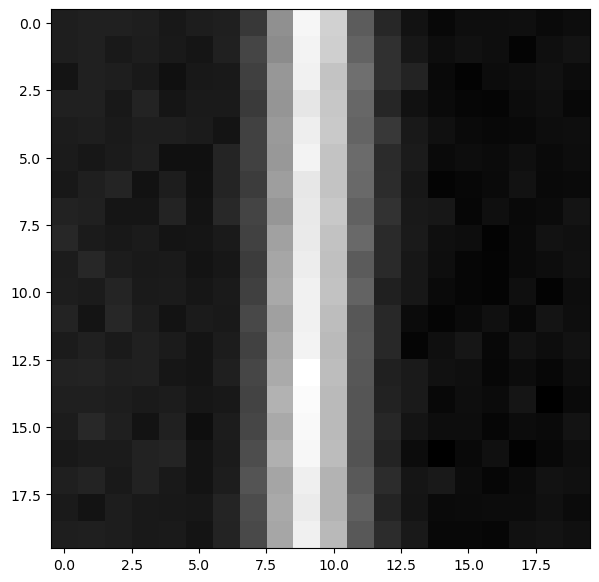

stamp info:  (0.99, 3)
[5, 5]


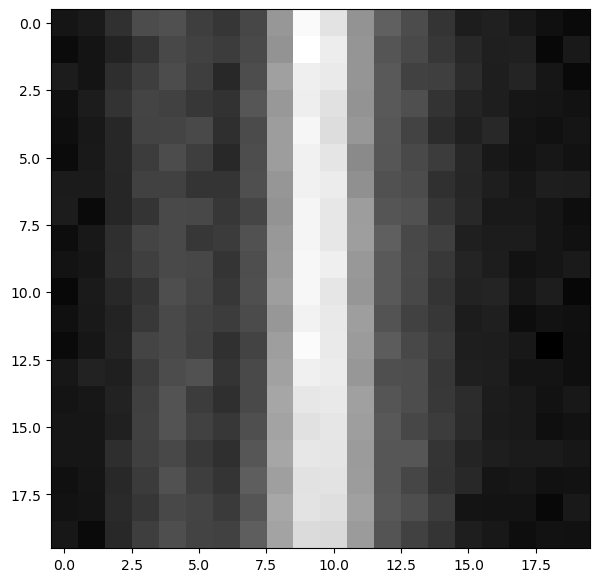

stamp info:  (0.99, 3)
[4, 4]


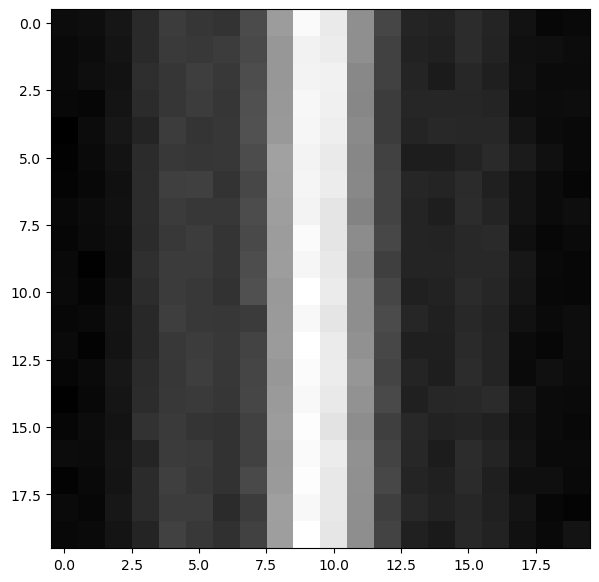

stamp info:  (0.99, 3)
[5, 5]


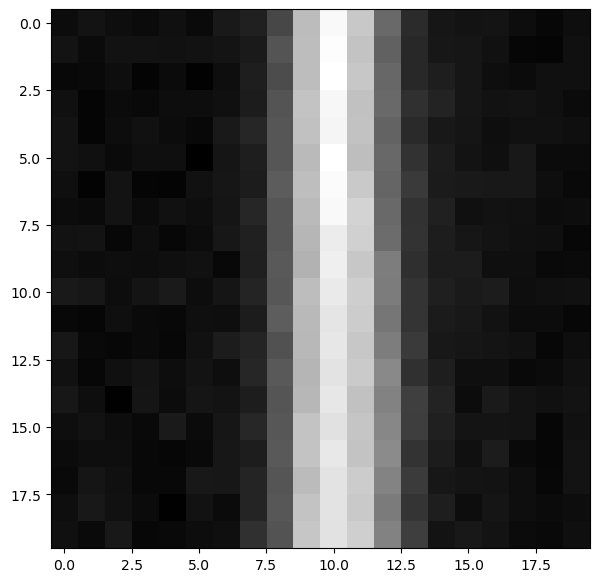

stamp info:  (0.99, 3)
[5, 5]


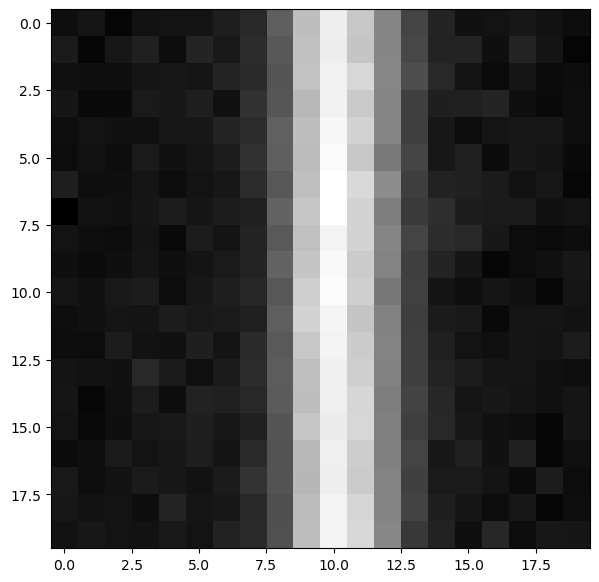

stamp info:  (0.99, 3)
[4, 4]


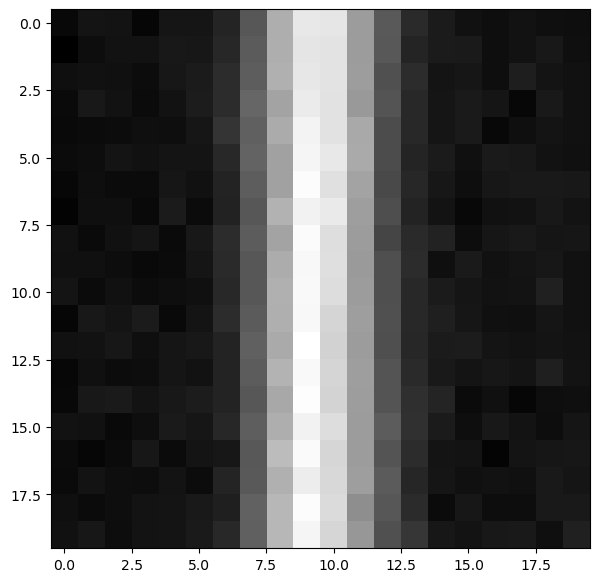

stamp info:  (0.99, 3)
[3, 3]


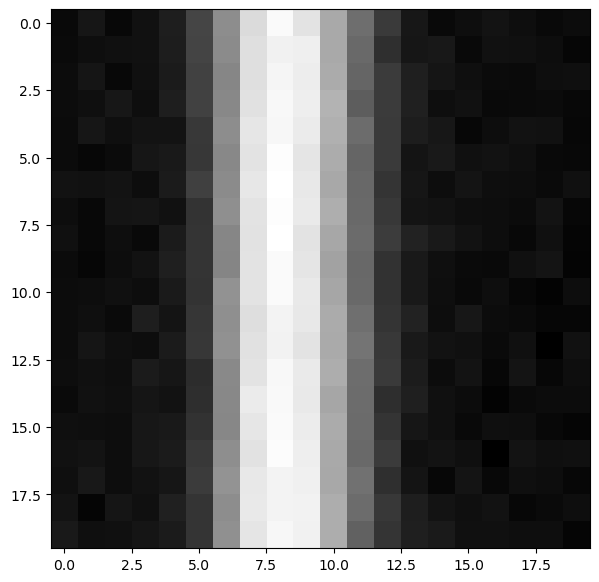

stamp info:  (0.99, 3)


In [139]:
np.shape(all_pos_stamps_15)

(895, 2)

In [157]:
np.unique(all_pos_stamps_info[: len(all_pos_stamps), 0])

array([ 1.01,  1.05,  1.1 ,  1.3 ,  1.5 ,  2.  ,  3.  ,  4.  ,  6.  ,
        8.  , 10.  ])

In [ ]:
our_feat_te_p8 = our_feat_te[our_outs_te == 0.8]

In [67]:
def save_predsarrays(image, model, wid, path):
    """
    This function will take an image and a cnn model and return an array
    of the transients found in that image.
    image: np array
    model: cnn model
    abst_thr: absolute probability threshold to consider a transient probability as a transient
    mult_thr: comparative probability threshold to consider a transient probability as a transient
    (aka the trans prob has to be x times larger than (streak prob + backg prob)
    wid: desired postage stamp width
    bg_thresh: thresh to consider the average background on a column to be "background",
    something like .1, used as criterion for determining cosmic rays
    path: path to save the array

    returns (and saves): array of length (number of transient detections),
    with elements of (detection row, detection column), transient detection size,
    realness (aka not-cosmic-ray)
    so a list of tuples, then an int, then the probability that its column is a streak
    to flag as a probable cosmic ray
    """

    nrow, ncol = image.shape
    print("getting postage stamps")
    stamps = gpsf.get_postage_stamps_full(image, 10)
    stampbatches = np.array_split(
        stamps, stamps.shape[0] // 20000
    )  # (image.shape[0] - 2 * wid) )
    # I WANNA CHANGE THIS TO SPEED HIM UP
    # so to be faster there should be less batches
    # so i want the second argument to be smaller
    # so i want the denomitor of the second argument to be larger
    preds = []
    print("getting predictions:")
    for stamps in tqdm(
        stampbatches
    ):  # getting all the predictions. does not renormalize
        pred_l = model.predict_on_batch(stamps)
        preds.append(pred_l)
    predsarray = np.concatenate(preds)
    # i would like to save the predsarrays i think. for reproducibility
    # np.save(path+"_predsarray", predsarray) #TURN THIS BACK ON LATER
    del stamps
    del stampbatches
    del preds
    gc.collect()
    return predsarray

In [68]:
predsarray1 = save_predsarrays(testimp, model, wid, path=None)

getting postage stamps
getting stamps now


  0%|          | 0/3052 [00:00<?, ?it/s]

getting predictions:


  0%|          | 0/466 [00:00<?, ?it/s]

2024-11-11 12:54:27.888867: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and shape [20042,20,20]
	 [[{{node Placeholder/_0}}]]
2024-11-11 12:54:29.937725: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and shape [20042,20,20]
	 [[{{node Placeholder/_0}}]]
2024-11-11 12:54:30.050947: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'Placeholder/_0' with dtype float and 

In [7]:
testimp = np.load(
    "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/images/ztf_20221014279051_000501_zr_c16_x_0025._implanted10.npy"
)

In [5]:
import get_postage_stamps as gpsf
import gc  # garbage collector
import precision_recall as pr

In [6]:
pray = np.load(
    "/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c16_x_0022._extraction_predsarray_4_predsarray.npy"
)

In [17]:
np.shape(pray)

(9339120, 5)

In [9]:
wid = 10
nrow, ncol = testimp.shape
pimg_pos = pray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = pray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = pray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = pray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = pray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

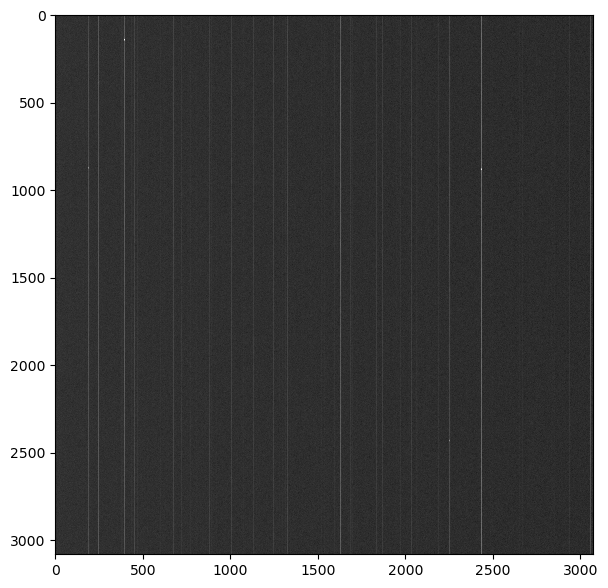

In [10]:
plt.imshow(np.sqrt(testimp))

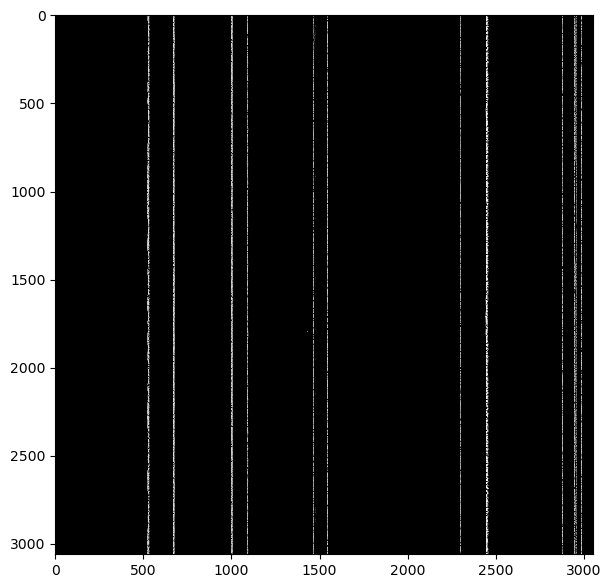

In [30]:
plt.imshow(pimg_streak.T)

In [34]:
def make_obj_list(image, predsarray, abst_thr, fname):
    wid = 10
    nrow, ncol = image.shape
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

    pimg_both = pimg_pos + pimg_neg

    structure = [[1, 1, 1], [1, 1, 1], [1, 1, 1]]  # for what counts as one object

    # FOR POS
    thrdet = pimg_pos > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_pos = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_pos = np.array(loc_list_pos)
    objsizes_pos = pr.get_objsizes(labs, nlabs)

    # brightnesses = np.zeros(len(loc_list))
    # # bg_thresh=.1
    # cosmicray = []
    # rows = np.zeros(len(loc_list))
    # cols = np.zeros(len(loc_list))
    # for k, loc in enumerate(loc_list):
    #     (row, col) = loc
    #     rows[k] = int(row)
    #     cols[k] = int(col)
    #     # print("loc = row,col= "+str(loc))
    #     # print(row)
    #     # print(col)
    #     colavg = np.average(pimg_bg.T[:,int(col)]) #not actually the column average
    #     #print("colavg: "+str(colavg) )
    #     # if colavg>bg_thresh: #column is mostly not background - can adjust this cutoff
    #     cosmicray.append(colavg)
    #     brightnesses[k] = image[int(row)+wid, int(col)+wid]

    fnames = np.full(len(loc_list_pos), fname)
    poses = np.full(len(loc_list_pos), "pos")
    poslist = (
        np.vstack((fnames, poses, loc_list_pos[:, 0], loc_list_pos[:, 1], objsizes_pos))
    ).T

    # FOR NEG
    thrdet = pimg_neg > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_neg = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_neg = np.array(loc_list_neg)

    objsizes_neg = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_neg), fname)
    negs = np.full(len(loc_list_neg), "neg")
    neglist = (
        np.vstack((fnames, negs, loc_list_neg[:, 0], loc_list_neg[:, 1], objsizes_neg))
    ).T

    # FOR CRS
    thrdet = pimg_cr > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_cr = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_cr = np.array(loc_list_cr)

    objsizes_cr = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_cr), fname)
    crs = np.full(len(loc_list_cr), "cr")
    print(np.shape(fnames))
    print(np.shape(crs))
    print(np.shape(loc_list_cr[:, 0]))
    print(np.shape(loc_list_cr[:, 1]))
    print(np.shape(objsizes_cr))
    crlist = (
        np.vstack((fnames, crs, loc_list_cr[:, 0], loc_list_cr[:, 1], objsizes_cr))
    ).T

    # FOR BOTH
    thrdet = pimg_both > abst_thr
    threshed = thrdet.T  # it takes the transposed pimg

    labs, nlabs = snm.label(threshed, structure)
    loc_list_both = snm.center_of_mass(threshed, labs, range(1, nlabs + 1))
    loc_list_both = np.array(loc_list_both)

    objsizes_both = pr.get_objsizes(labs, nlabs)

    fnames = np.full(len(loc_list_both), fname)
    boths = np.full(len(loc_list_both), "both")
    bothlist = (
        np.vstack(
            (fnames, boths, loc_list_both[:, 0], loc_list_both[:, 1], objsizes_both)
        )
    ).T

    del pimg_cr
    del pimg_pos
    del pimg_neg
    del pimg_bg
    del pimg_streak
    del thrdet
    del loc_list_pos
    del loc_list_neg
    del objsizes_pos
    del objsizes_neg
    del labs
    del threshed
    gc.collect()

    listlist = np.vstack((poslist, neglist, crlist, bothlist))
    alllist = pd.DataFrame(listlist)

    alllist.rename(
        columns={
            0: "filename",
            1: "type",
            2: "row_from_nn",
            3: "col_from_nn",
            4: "detection_size",
        },
        inplace=True,
    )

    alllist[["row_from_nn", "col_from_nn", "detection_size"]] = alllist[
        ["row_from_nn", "col_from_nn", "detection_size"]
    ].apply(pd.to_numeric)
    # np.save(path, n_loc_size_ray_b)
    return poslist, neglist, crlist, bothlist, alllist

In [4]:
import pandas as pd

In [35]:
poslist, neglist, crlist, bothlist, alllist = make_obj_list(
    testimp, pray, 0.9999, "fname"
)

(15,)
(15,)
(15,)
(15,)
(15,)


In [36]:
alllist["detection_size"] > 15

0      False
1      False
2      False
3      False
4      False
       ...  
317    False
318    False
319    False
320    False
321    False
Name: detection_size, Length: 322, dtype: bool

In [37]:
alllist[alllist["detection_size"] > 15]

,filename,type,row_from_nn,col_from_nn,detection_size
22,fname,pos,1801.414634,1425.243902,41
23,fname,pos,1805.588235,1501.352941,17
39,fname,pos,2654.821429,144.000000,28
45,fname,neg,53.500000,241.000000,16
47,fname,neg,68.407407,241.296296,27
52,fname,neg,143.823529,2445.588235,17
54,fname,neg,182.181818,2445.772727,22
55,fname,neg,263.782609,2445.086957,23
69,fname,neg,589.363636,339.636364,22
112,fname,neg,1780.888889,2444.888889,18


In [28]:
alllist

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,pos,78.6923076923077,2445.6923076923076,13
1,fname,pos,121.0,2445.0,3
2,fname,pos,134.5,2445.0,4
3,fname,pos,190.75,2445.25,4
4,fname,pos,255.5,2445.0,2
...,...,...,...,...,...
317,fname,both,2831.5,2445.0,4
318,fname,both,2839.6666666666665,2445.8888888888887,9
319,fname,both,2910.0,2445.0,1
320,fname,both,2940.0,2451.0,1


In [147]:
import pandas as pd

In [268]:
df_detections_both = pd.DataFrame(bothlist)

In [269]:
df_detections_both.rename(
    columns={
        0: "filename",
        1: "type",
        2: "row_from_nn",
        3: "col_from_nn",
        4: "detection_size",
    },
    inplace=True,
)

In [270]:
df_detections_both

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,both,131.9938080495356,387.04334365325076,323
1,fname,both,121.4,396.6,5
2,fname,both,130.3,396.6,20
3,fname,both,161.5,1623.0,2
4,fname,both,170.0,1618.0,3
5,fname,both,363.4375,1825.75,16
6,fname,both,374.04545454545456,238.70454545454547,44
7,fname,both,378.6666666666667,1826.4285714285713,21
8,fname,both,383.2413793103448,238.82758620689654,29
9,fname,both,698.4,822.2,5


In [256]:
df_detections_pos

,filename,type,row_from_nn,col_from_nn,detection_size
0,fname,pos,121.4,396.6,5
1,fname,pos,130.52884615384616,387.1730769230769,104
2,fname,pos,374.04545454545456,238.70454545454547,44
3,fname,pos,862.6463414634146,181.0731707317073,82
4,fname,pos,860.5,2435.0,2
5,fname,pos,870.7142857142857,2425.704081632653,98
6,fname,pos,1876.7368421052631,0.47368421052631576,19
7,fname,pos,2067.878787878788,1318.5454545454545,33
8,fname,pos,2411.5,2251.0,2
9,fname,pos,2420.57,2241.65,100


Threshold:  0.9999


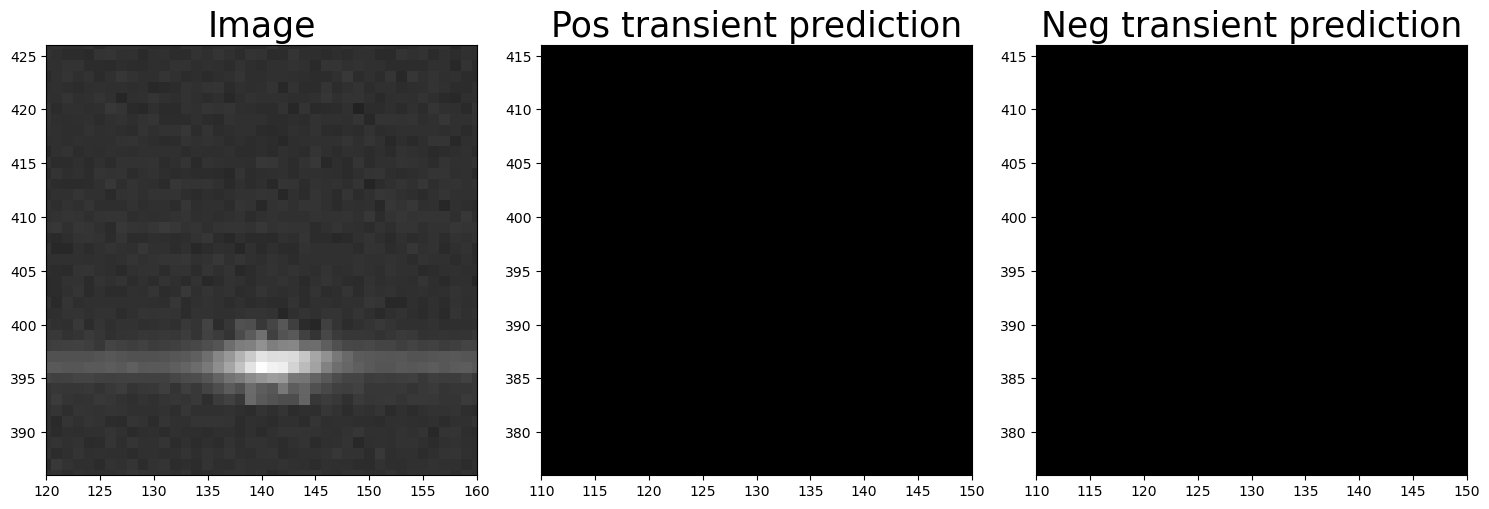

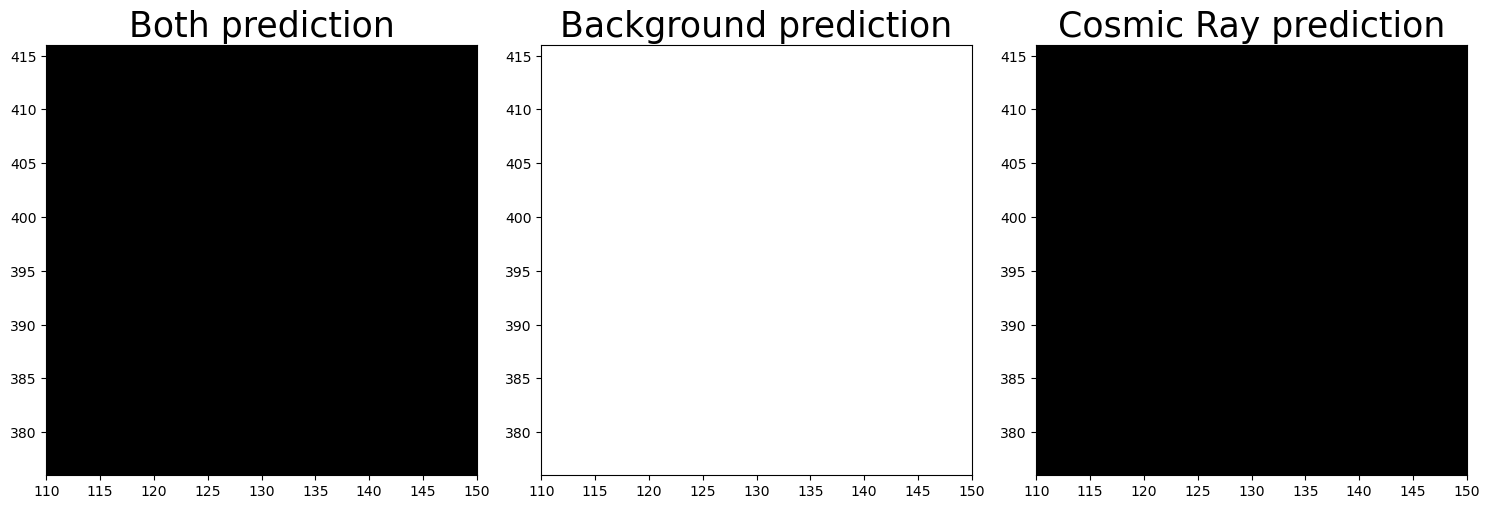

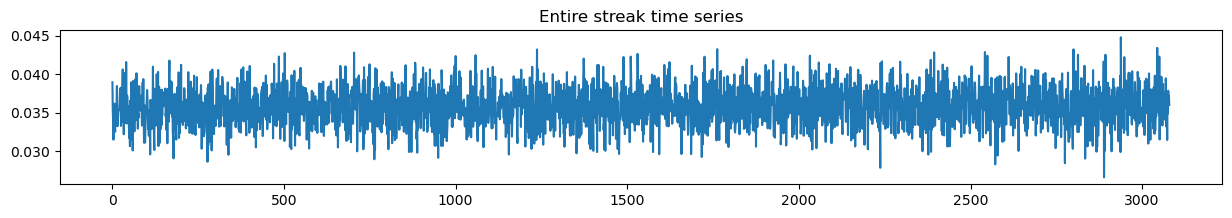

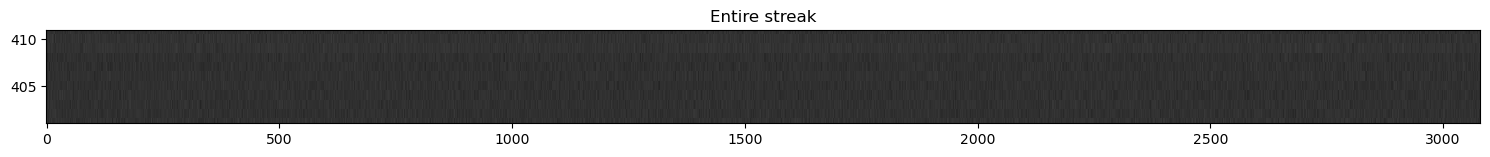

In [14]:
zoominthere2((130, 396), testimp, pray, 0.9999, 10)

Threshold:  0.9999


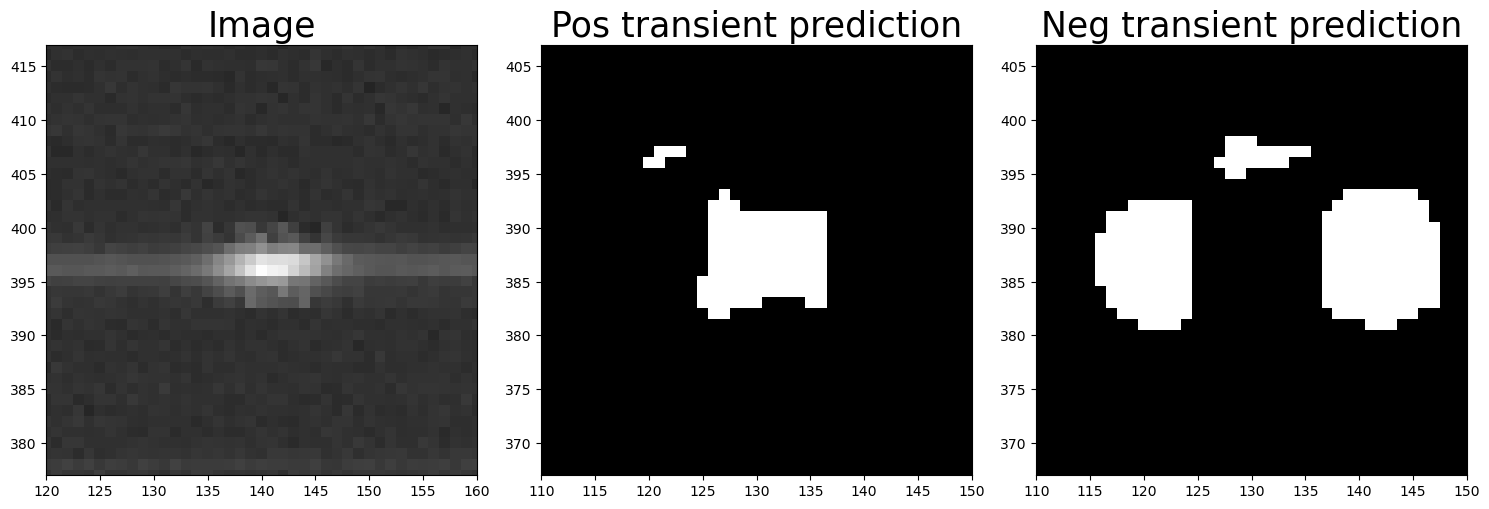

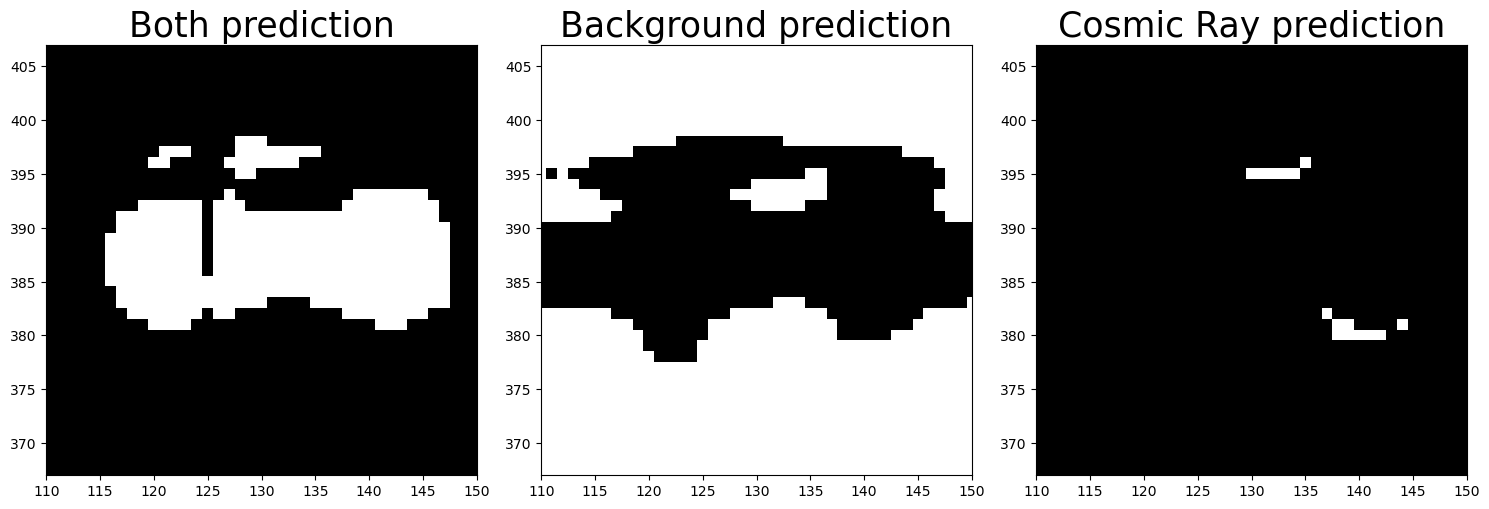

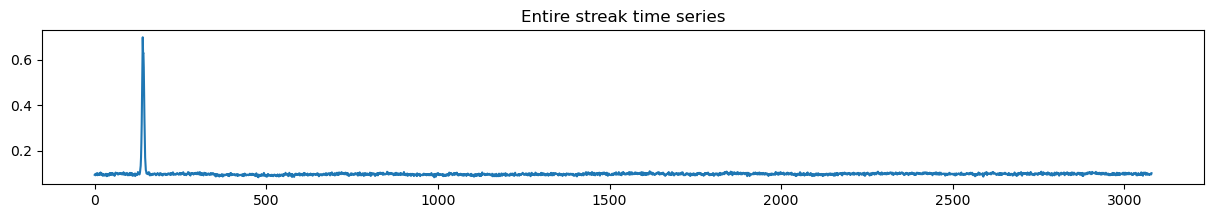

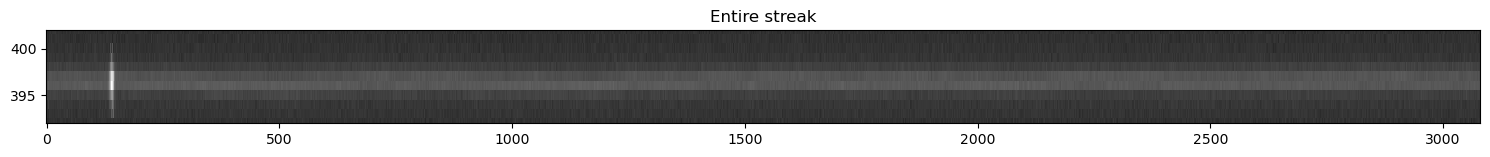

In [69]:
zoominthere2((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.99


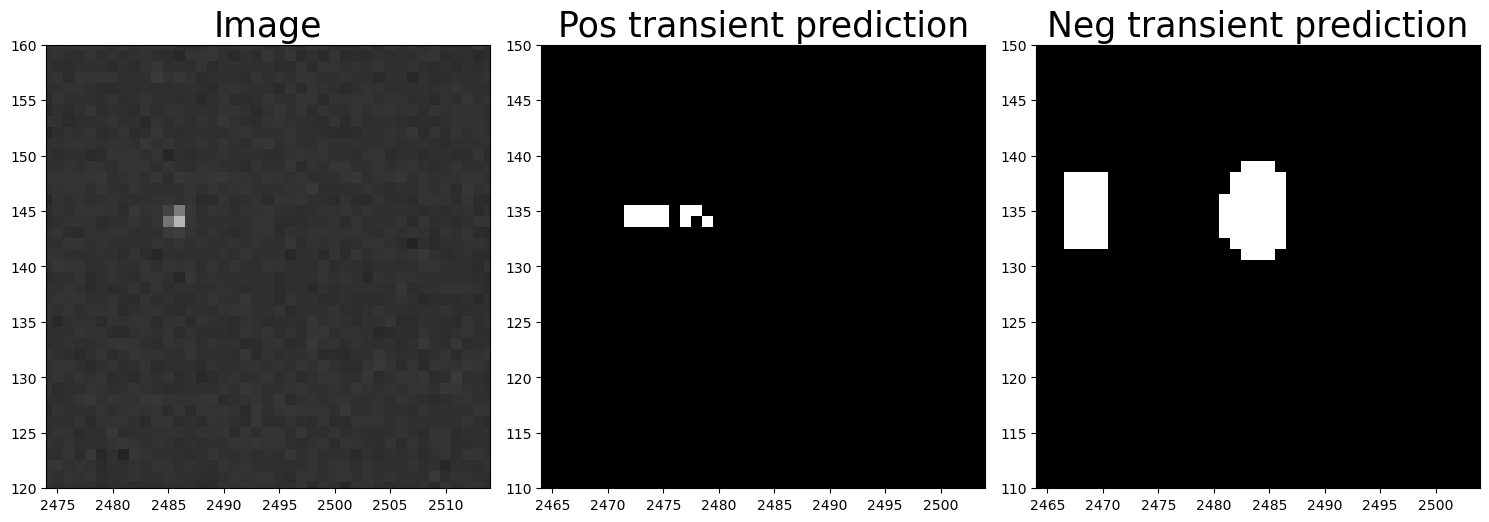

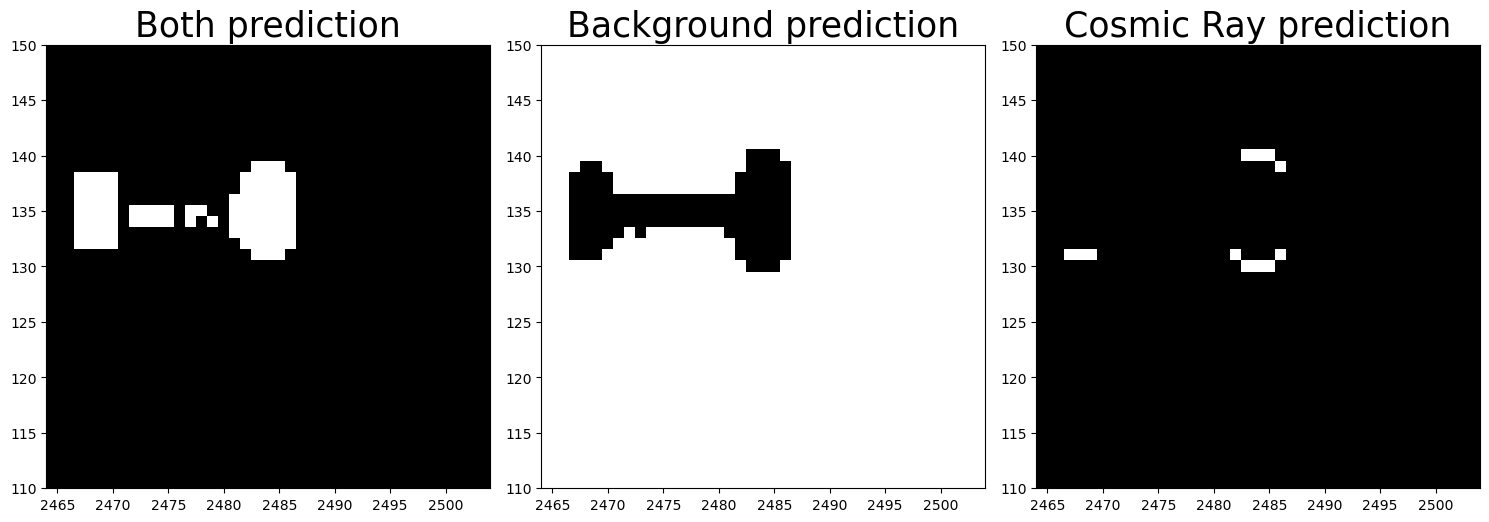

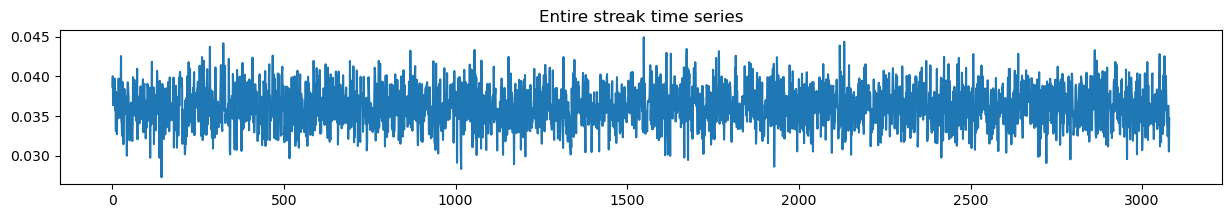

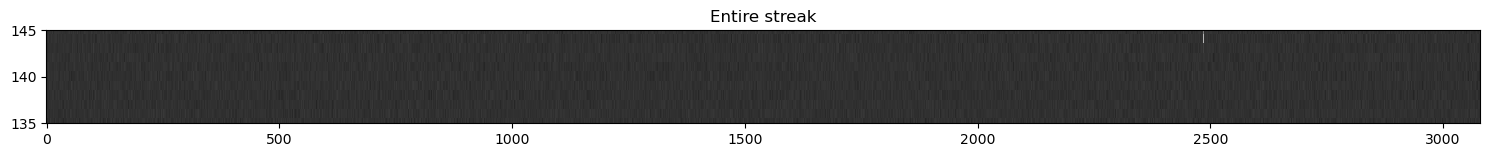

In [303]:
zoominthere2((2484, 130), testimp, pray, 0.99, 10)

Threshold:  0.5


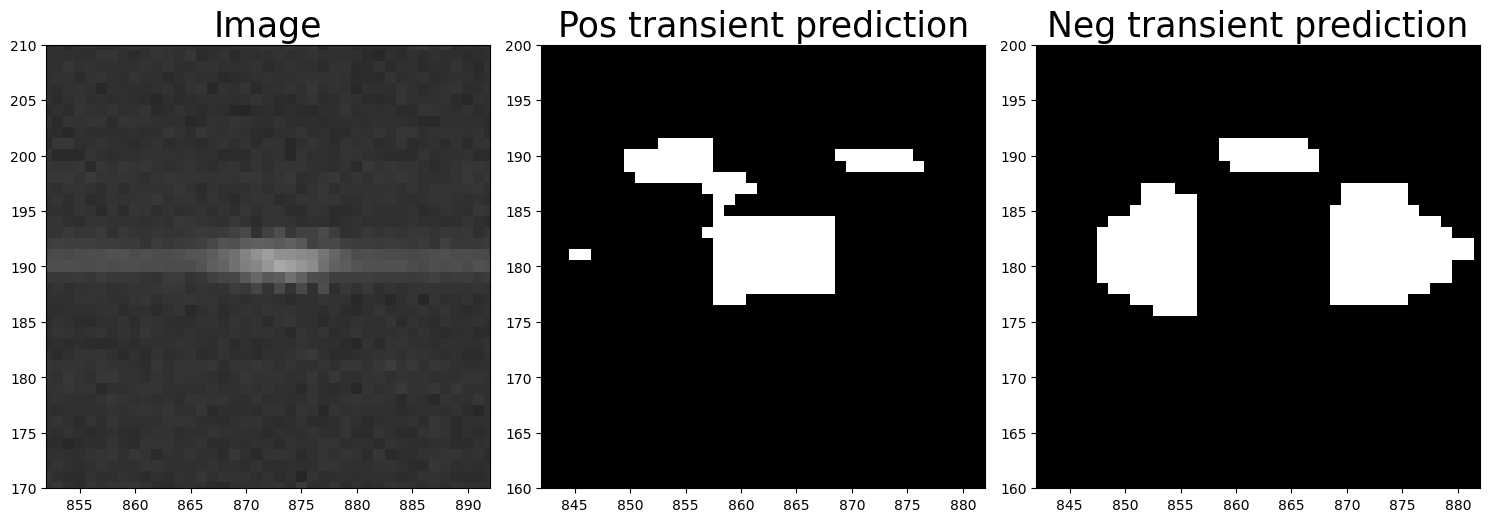

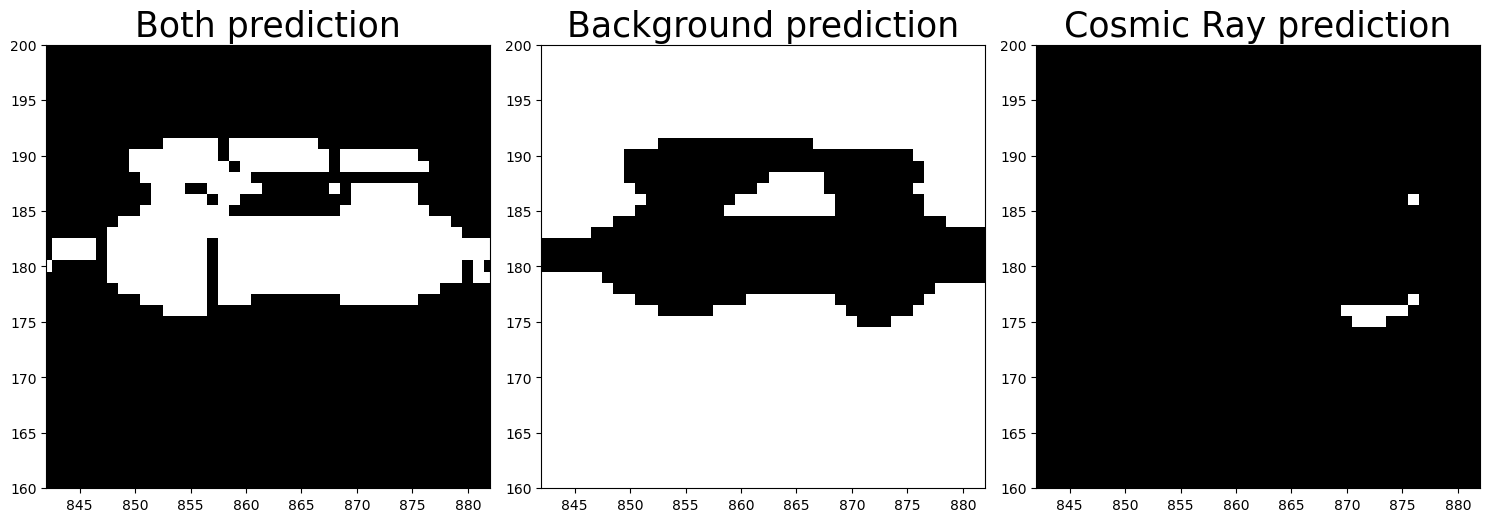

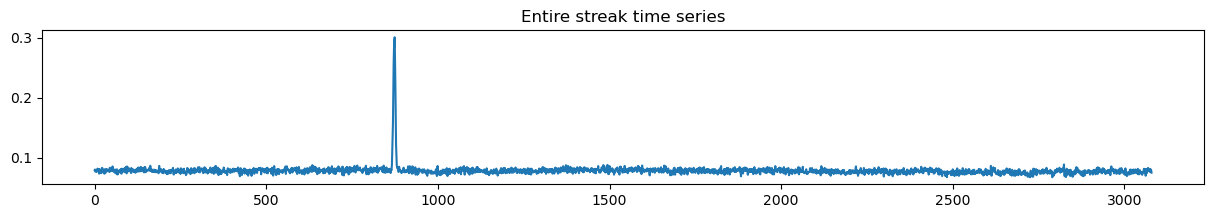

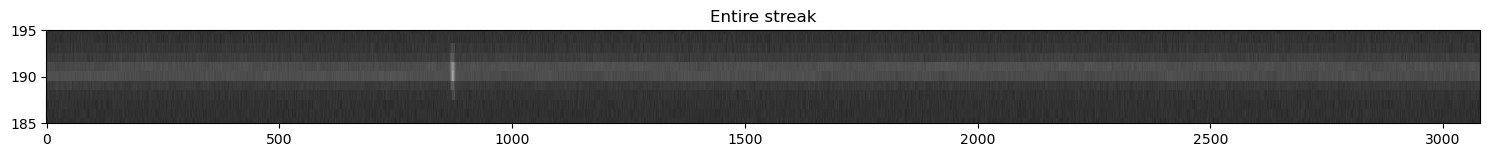

In [304]:
zoominthere2((862, 180), testimp, pray, 0.5, 10)

In [46]:
def zoominthere2(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg
    wid = offset
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow((pimg_pos > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Pos transient prediction", fontsize=25)
    ax[2].imshow((pimg_neg > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Neg transient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    row, col = loc
    # print(loc)
    ax[0].imshow((pimg_both > thr))
    ax[0].set_ylim(col - 20, col + 20)
    ax[0].set_xlim(row - 20, row + 20)
    ax[0].set_title("Both prediction", fontsize=25)
    # plt.colorbar()
    ax[1].imshow((pimg_bg > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Background prediction", fontsize=25)
    ax[2].imshow((pimg_cr > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Cosmic Ray prediction", fontsize=25)
    plt.tight_layout()
    # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.1)
    plt.show()

    fig2, ax2 = plt.subplots(1, 1, figsize=(15, 2))
    ax2.plot(
        (
            image[:, int(col + wid)]
            + image[:, int(col + wid) + 1]
            + image[:, int(col + wid) - 1]
        )
        / 3
    )
    ax2.set_title("Entire streak time series")
    plt.show()
    fig3, ax3 = plt.subplots(1, 1, figsize=(15, 2))
    ax3.imshow(np.sqrt(image.T), aspect=20)
    ax3.set_ylim(col + wid - 5, col + wid + 5)
    ax3.set_title("Entire streak")
    plt.tight_layout()
    plt.show()

Threshold:  0.9999


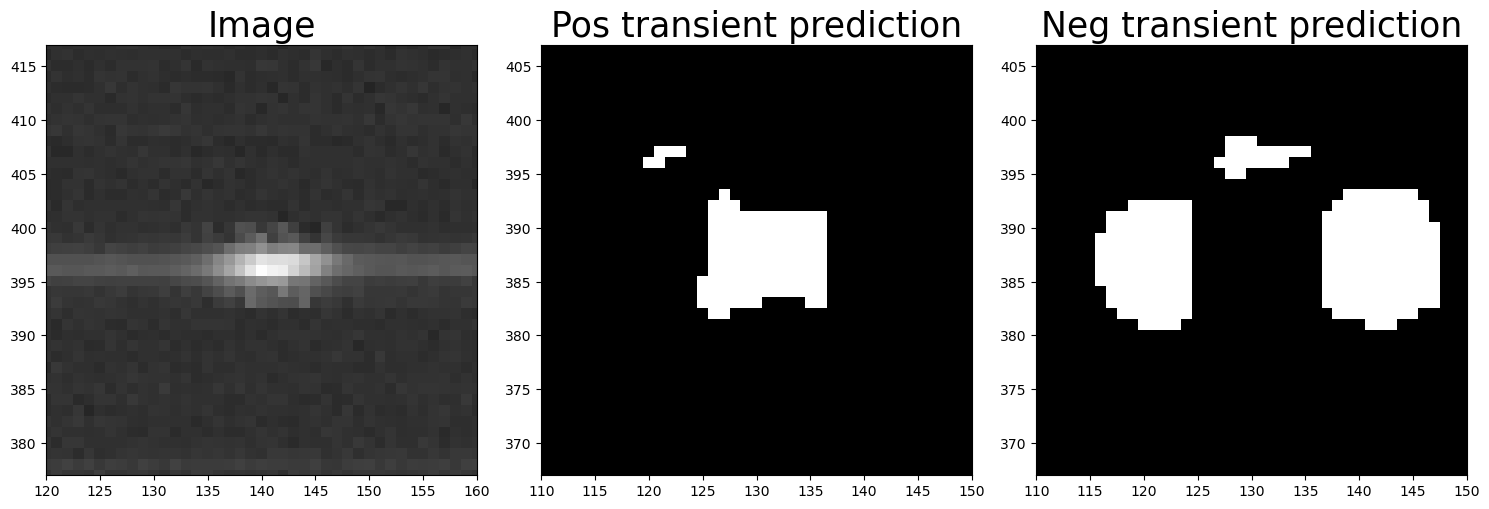

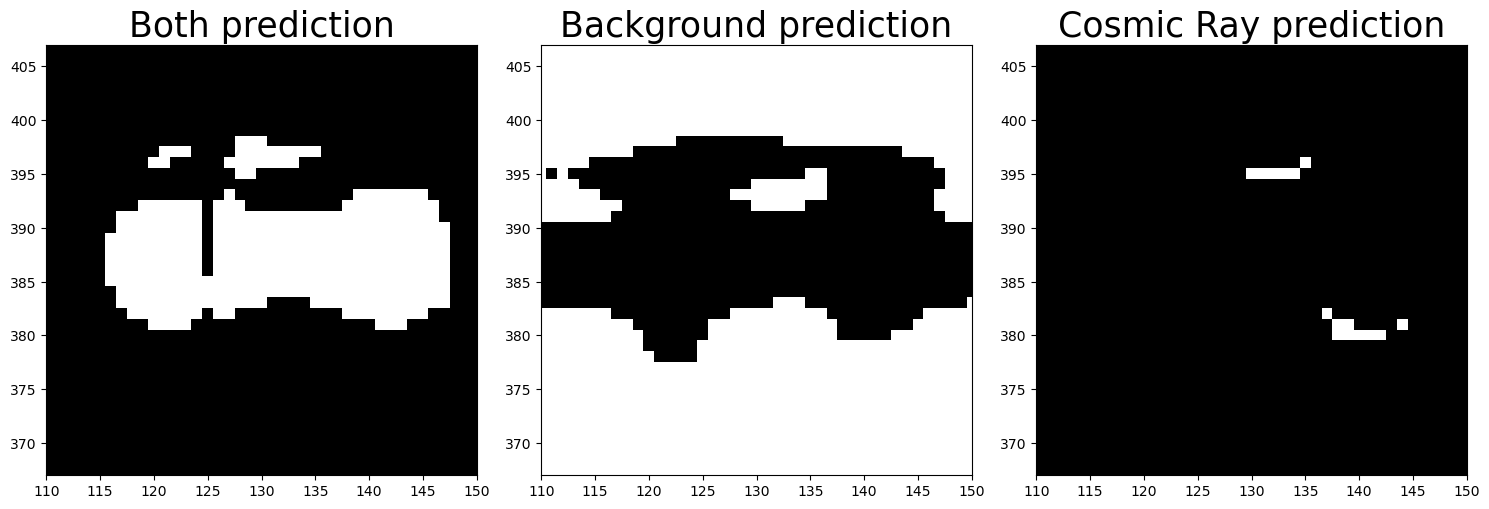

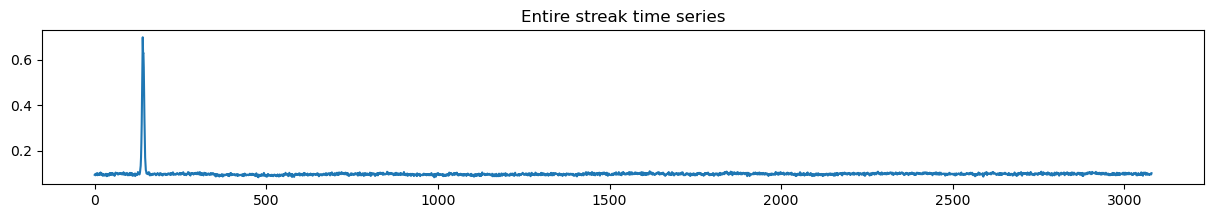

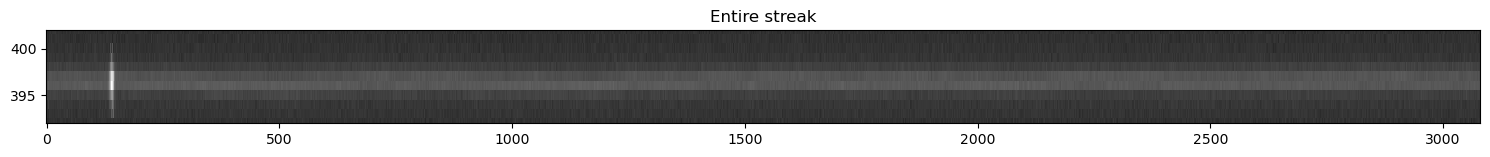

In [71]:
zoominthere2((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.5


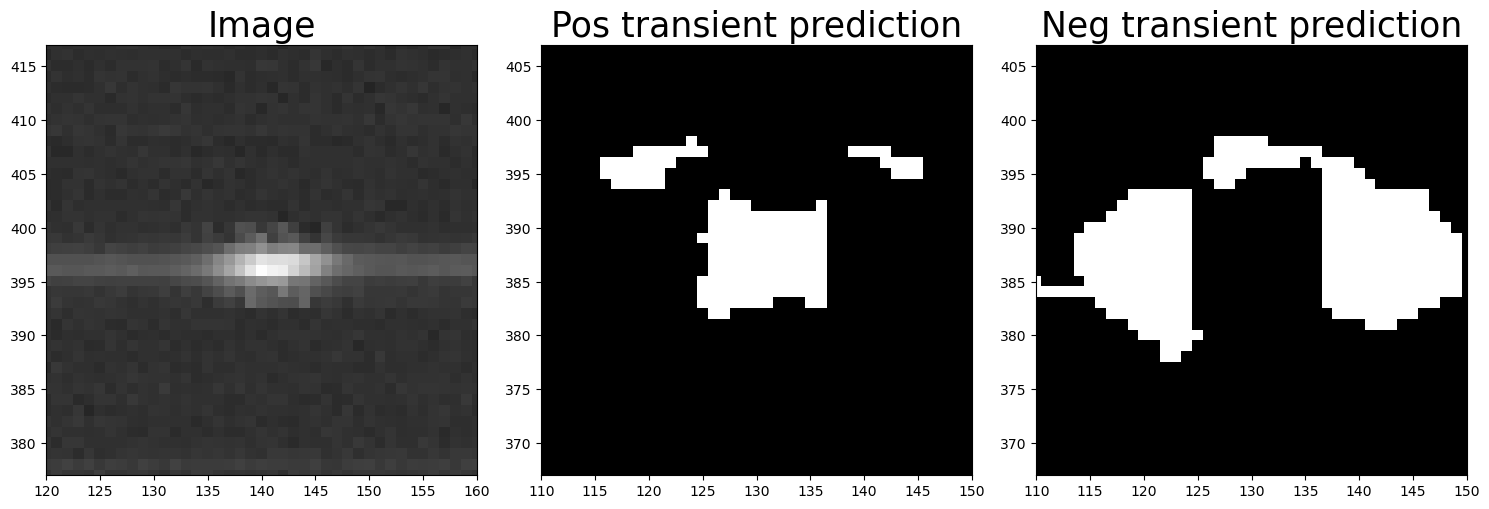

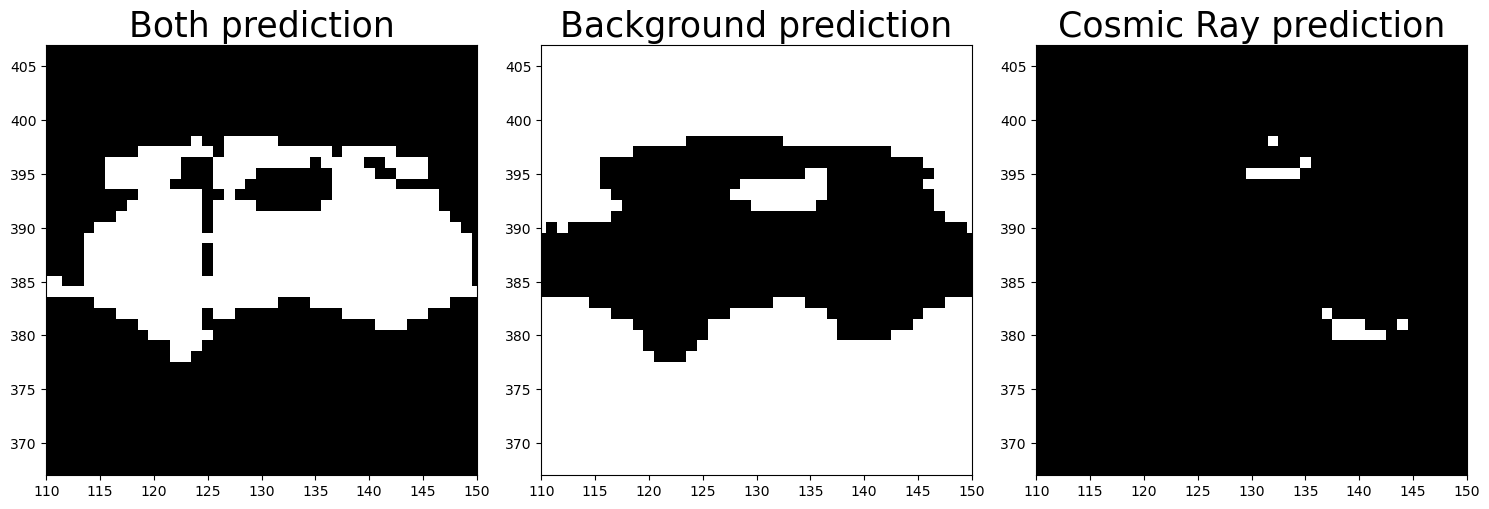

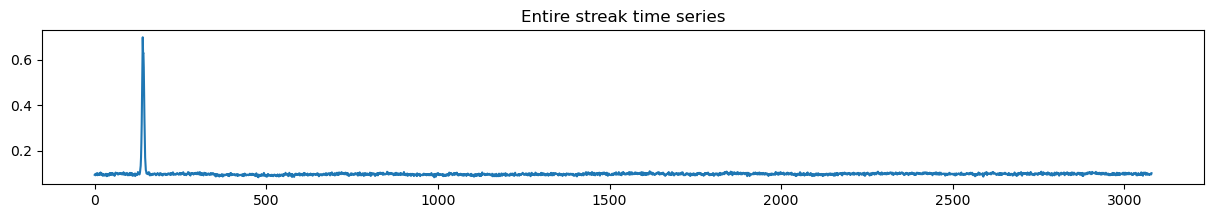

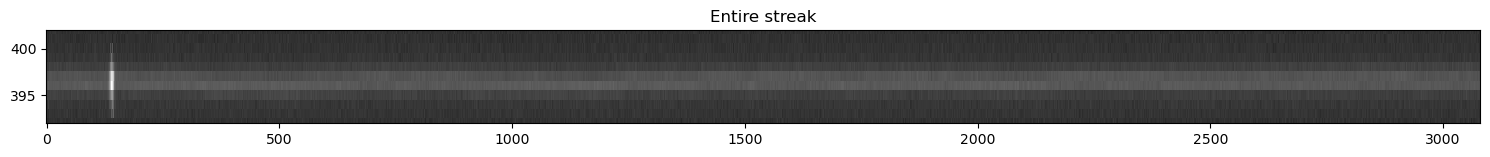

In [82]:
zoominthere2((130, 387), testimp, predsarray1, 0.5, 10)

In [72]:
pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_both = pimg_pos + pimg_neg

In [299]:
direcname = str(1020)
fname = "ztf_20221020297847_000449_zr_c15_x_0002.fits.fz"
fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)
path = fpath + fname
hdul = fits.open(path)
file1_array = hdul[1].data

In [298]:
# image2 =  np.load('/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c15_x_0002.


predsarray2 = np.load(
    "/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020297847_000449_zr_c15_x_0002._extraction_predsarray_1_predsarray.npy"
)

In [281]:
predsarray.shape

(9339120, 5)

In [83]:
pimg_pos = predsarray1[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_bg = predsarray1[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_streak = predsarray1[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_neg = predsarray1[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_cr = predsarray1[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
pimg_both = pimg_pos + pimg_neg

In [92]:
L_thr = pimg_pos > 0.9999
labs, nlabs = snm.label(L_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

(110.0, 150.0)

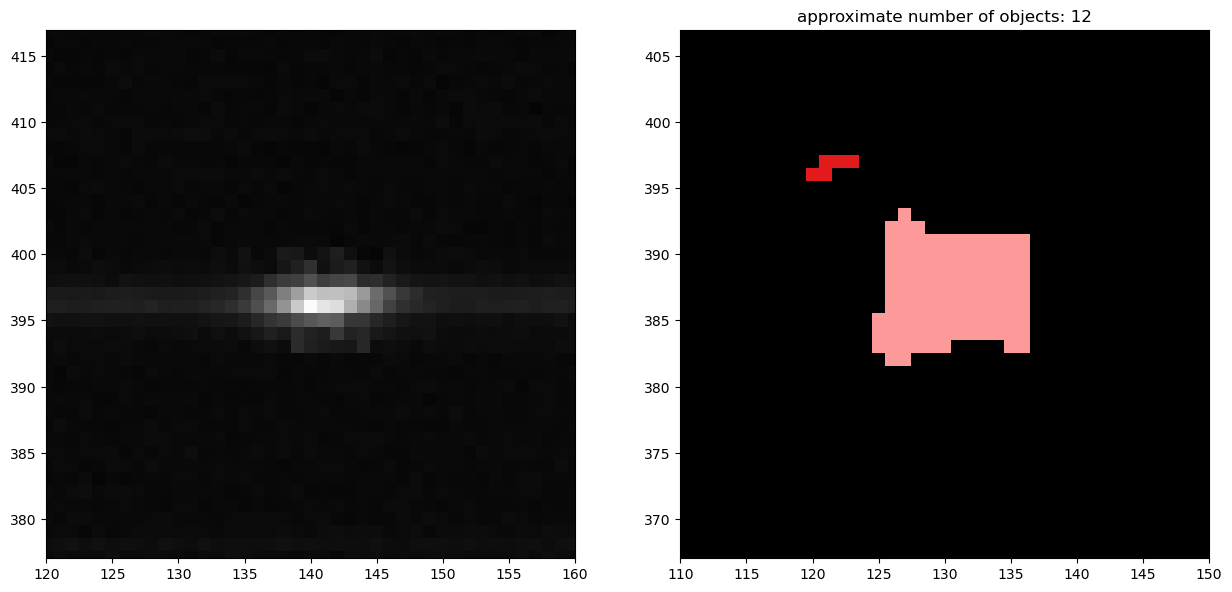

In [95]:
# -- display thresholded image and labels

row, col = (130, 387)
fig, ax = plt.subplots(1, 2, figsize=(15, 10))

ax[0].imshow(testimp.T)
ax[1].imshow(labs, cmap="Paired", alpha=L_thr.astype(float))
# otherwise "none" and "lowest numbered object" will be the same
# slpha is a float between 0 and 1, it's opaqueness

ax[1].set_facecolor("black")
ax[1].set_title("approximate number of objects: {0}".format(nlabs))

ax[0].set_ylim(col - 20 + wid, col + 20 + wid)
ax[0].set_xlim(row - 20 + wid, row + 20 + wid)

ax[1].set_ylim(col - 20, col + 20)
ax[1].set_xlim(row - 20, row + 20)

In [129]:
def zoominthere_five(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg

    pos_thr = pimg_pos > thr
    pos_labs, nlabs = snm.label(pos_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    neg_thr = pimg_neg > thr
    pos_labs, nlabs = snm.label(neg_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    both_thr = pimg_both > thr
    pos_labs, nlabs = snm.label(both_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow(pos_thr, cmap="Paired", alpha=pos_thr.astype(float))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow(neg_thr, cmap="Paired", alpha=neg_thr.astype(float))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow(both_thr, cmap="Paired", alpha=both_thr.astype(float))
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_facecolor("black")

    plt.tight_layout()
    plt.show()

Threshold:  0.9999


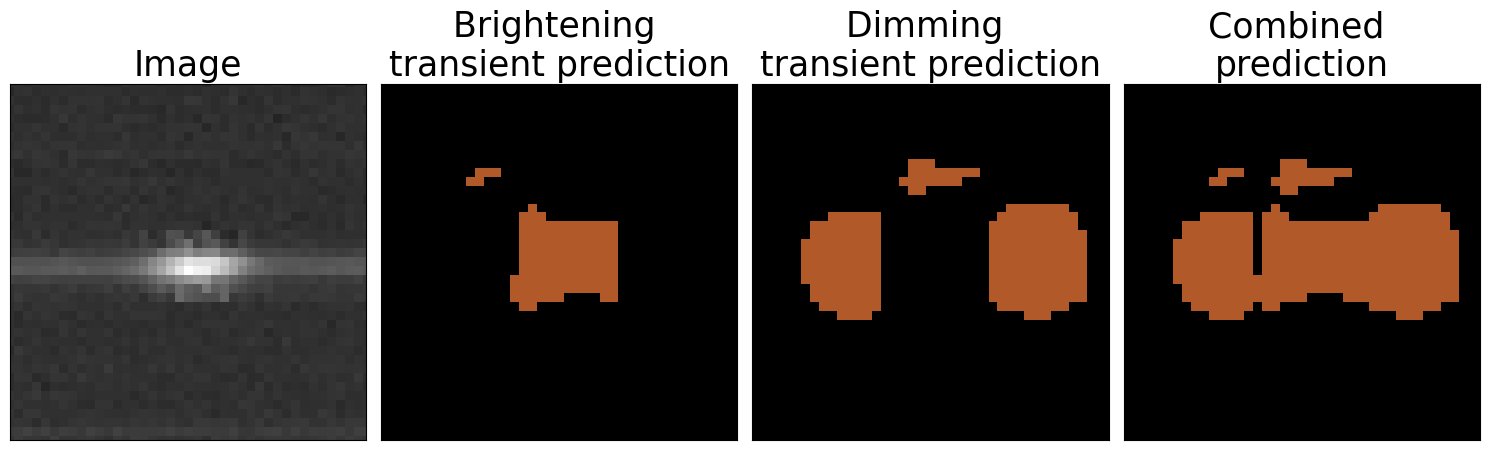

In [130]:
zoominthere_five((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0.9999


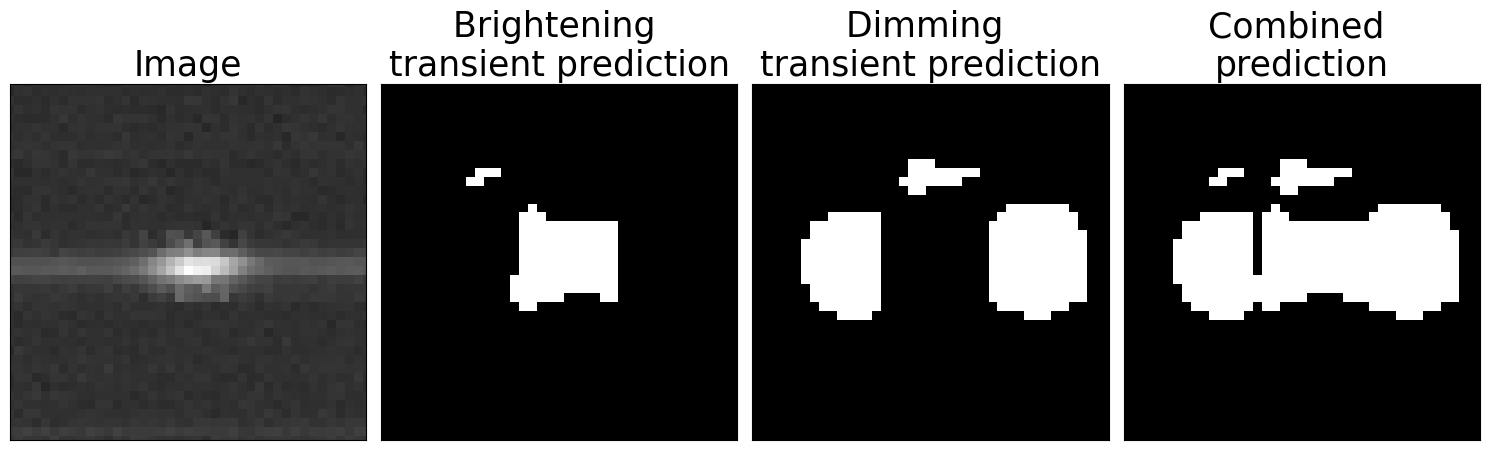

In [134]:
zoominthere_four((130, 387), testimp, predsarray1, 0.9999, 10)

Threshold:  0


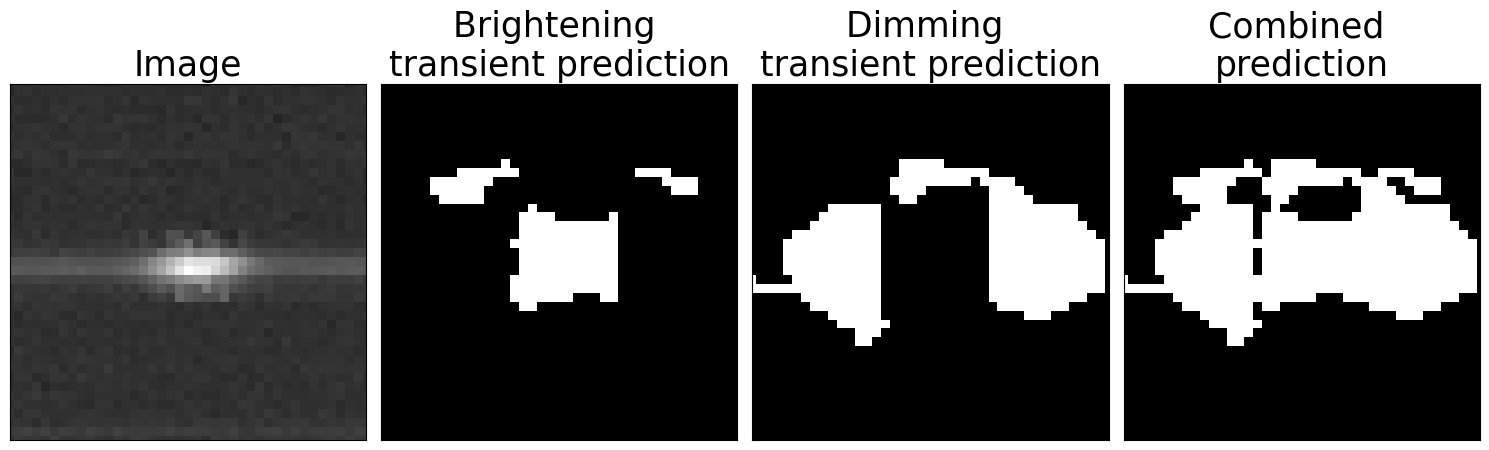

In [147]:
zoominthere_max((130, 387), testimp, predsarray1, 0, 10)

In [131]:
def zoominthere_four(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)

    pimg_both = pimg_pos + pimg_neg
    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow((pimg_pos > thr))
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow((pimg_neg > thr))
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow((pimg_both > thr))
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])

    plt.tight_layout()
    plt.show()

In [145]:
def zoominthere_max(loc, image, predsarray, thr, offset):
    """
    sometimes i see a transient location come up and i'm like
    what is that. can we zoom in there
    loc: (row, column) from nn prediction (not lined up with image)
    image: array (streak image)
    pimg: array (probability image)
    offset: difference between rows/cols of original and pimg (usually it is wid (10))
    returns: nothing but shows plot of zoomed in
    """
    nrow, ncol = image.shape
    wid = 10
    pimg_pos = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_bg = predsarray[:, 0].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_streak = predsarray[:, 4].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_cr = predsarray[:, 3].reshape(ncol - 2 * wid, nrow - 2 * wid)
    pimg_both = pimg_pos + pimg_neg

    pos_thr = pimg_pos > (pimg_bg + pimg_streak + pimg_cr + pimg_neg)
    pos_labs, nlabs = snm.label(pos_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    neg_thr = pimg_neg > (pimg_bg + pimg_streak + pimg_cr + pimg_pos)
    pos_labs, nlabs = snm.label(neg_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    both_thr = pos_thr + neg_thr
    pos_labs, nlabs = snm.label(both_thr, structure=[[1, 1, 1], [1, 1, 1], [1, 1, 1]])

    # print(pimg_both)

    wid = offset
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    row, col = loc
    print("Threshold: ", thr)
    ax[0].imshow(np.sqrt(image.T))
    ax[0].set_ylim(col + wid - 20, col + wid + 20)
    ax[0].set_xlim(row - 20 + wid, row + 20 + wid)
    ax[0].set_title("Image", fontsize=25)
    ax[1].imshow(pos_thr)
    ax[1].set_ylim(col - 20, col + 20)
    ax[1].set_xlim(row - 20, row + 20)
    ax[1].set_title("Brightening \ntransient prediction", fontsize=25)
    ax[2].imshow(neg_thr)
    ax[2].set_ylim(col - 20, col + 20)
    ax[2].set_xlim(row - 20, row + 20)
    ax[2].set_title("Dimming \ntransient prediction", fontsize=25)
    # plt.colorbar()
    # ax[1].plot((image[:,int(col+wid)]+image[:,int(col+wid)+1]+image[:,int(col+wid)-1])/3)
    # ax[1].set_xlim(row-20+wid,row+20+wid)
    # ax[1].set_title("Time series average of image row "
    #                 +str(int(col+wid))
    #                +" and adjacent")

    ax[3].imshow(both_thr)
    ax[3].set_ylim(col - 20, col + 20)
    ax[3].set_xlim(row - 20, row + 20)
    ax[3].set_title("Combined \nprediction", fontsize=25)
    for axis in ax:
        axis.set_xticks([])
        axis.set_yticks([])
        # axis.set_facecolor("black")

    plt.tight_layout()
    plt.show()

In [3]:



fpath_streak = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/"


# for i, file in enumerate(os.listdir(fpath_streak)):
#     image_filename = os.fsdecode(file)
#     image_filename_full = fpath_streak + image_filename
#     print(image_filename)
#     streak = np.load(image_filename_full)
#     streak_arr = np.array(streak)
#     print(np.shape(streak))
#     # all_trans_stamps.append(trans_arr)
#     if i == 0:
#         all_streak_stamps = streak_arr
#     else:
#         all_streak_stamps = np.concatenate((all_streak_stamps, streak_arr), axis=0)

image_path = fpath_streak + "images/"
info_path = fpath_streak + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_streak_stamps = trans_arr
        all_streak_stamps_info = infos_arr
    else:
        all_streak_stamps = np.concatenate((all_streak_stamps, trans_arr), axis=0)
        all_streak_stamps_info = np.concatenate((all_streak_stamps_info, infos_arr), axis=0)


# In[4]:


np.shape(all_streak_stamps)


# In[5]:


fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_pos/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)


# In[6]:


np.shape(all_pos_stamps)


# In[7]:


np.shape(all_pos_stamps)


# In[8]:


fpath_cr = "/lustre/lrspec/ZTF_data/training_aug24/stamps_cr/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_cr)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_cr + image_filename
    print(image_filename)
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    print(np.shape(trans))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_cr_stamps = trans
    else:
        all_cr_stamps = np.concatenate((all_cr_stamps, trans_arr), axis=0)


# In[9]:


np.shape(all_cr_stamps)


# In[10]:


fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_neg/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_neg_stamps = trans_arr
        all_neg_stamps_info = infos_arr
    else:
        all_neg_stamps = np.concatenate((all_neg_stamps, trans_arr), axis=0)
        all_neg_stamps_info = np.concatenate((all_neg_stamps_info, infos_arr), axis=0)


# In[11]:


np.shape(all_neg_stamps)


# In[12]:


fpath_bg = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_background/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

# for i, file in enumerate(os.listdir(fpath_bg)):
#     image_filename = os.fsdecode(file)
#     image_filename_full = fpath_bg + image_filename
#     print(image_filename)
#     bg = np.load(image_filename_full)
#     bg_arr = np.array(bg)
#     print(np.shape(bg))
#     # all_trans_stamps.append(trans_arr)
#     if i == 0:
#         all_bg_stamps = bg
#     else:
#         all_bg_stamps = np.concatenate((all_bg_stamps, bg_arr), axis=0)

image_path = fpath_bg + "images/"
info_path = fpath_bg + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:50]  + "info_"+image_filename[50:]
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
        # Add file index as first column
    file_idx = np.full((infos_arr.shape[0], 1), i)
    infos_arr = np.concatenate([file_idx, infos_arr], axis=1)
    

    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_bg_stamps = trans_arr
        all_bg_stamps_info = infos_arr
    else:
        all_bg_stamps = np.concatenate((all_bg_stamps, trans_arr), axis=0)
        all_bg_stamps_info = np.concatenate((all_bg_stamps_info, infos_arr), axis=0)






    
pos_use, bness_pos_use, lens_pos_use = split_stamps(all_pos_stamps, all_pos_stamps_info, 57400/6, random_state=301, return_test=False)

neg_use, bness_neg_use, lens_neg_use = split_stamps(all_neg_stamps, all_neg_stamps_info, 57400/6, random_state=302, return_test=False)
   
streaks_use, ignore, ignore2 = split_stamps(all_streak_stamps, all_streak_stamps_info, 57400/6, random_state=303, return_test=False)

bg_use, ignore, ignore2 = split_stamps(all_bg_stamps, all_bg_stamps_info, 57400/3, random_state=304, return_test=False)
    




# Process bness and lens
bness = np.concatenate(
    (
        np.full(len(bg_use), 0.),
        bness_pos_use,
        bness_neg_use,
        np.full(len(all_cr_stamps), 0.),
        np.full(len(streaks_use), 0.),
    )
)

lens = np.concatenate(
    (
        np.full(len(bg_use), 0.),
        lens_pos_use,
        lens_neg_use,
        np.full(len(all_cr_stamps), 0.),
        np.full(len(streaks_use), 0.),
    )
)

targ = np.concatenate(
    (
        np.full(len(bg_use), 0.),
        np.full(len(pos_use), 1.),
        np.full(len(neg_use), 2.),
        np.full(len(all_cr_stamps), 3.),
        np.full(len(streaks_use), 4.),
    )
)


# Combine all features
feat = np.concatenate(
    (bg_use, pos_use, neg_use, all_cr_stamps, streaks_use),
    axis=0,
)


# # Split features into training and testing sets once
# feat_tr, feat_te, bness_tr, bness_te, lens_tr, lens_te, targ_tr, targ_te = train_test_split(feat, bness, lens, targ, random_state=302)



ztf_20220820237546_000798_zr_c06_x_0000._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0006._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c13_x_0002._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0007._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c06_x_0003._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c14_x_0000._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c05_x_0007._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0025._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c03_x_0005._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c01_x_0001._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0010._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c02_x_0011._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c10_x_0000._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802

In [6]:
feat.shape

(189987, 20, 20)

In [9]:
info = np.array([bness, lens, targ, np.zeros(len(bness), dtype=float)]).T.copy()

In [8]:
len(feat)

189987

In [72]:
def split_stamps(stamps, info, train_size, random_state, return_test=False, numinid=5, numthesame=5, return_mask=False):
    transient_ids = np.unique(info[:, :numinid], axis=0)
    if train_size==.75:
            # Split the transient IDs
        train_ids, test_ids = train_test_split(
            transient_ids, 
            train_size=train_size,
            random_state=random_state
        )
    else:
        # Split the transient IDs
        train_ids, test_ids = train_test_split(
            transient_ids, 
            train_size=int(train_size/numthesame),
            random_state=random_state
        )

    # Create a mask for training data
    train_mask = np.isin(
        info[:, :numinid].view([('', info.dtype)] * numinid),
        train_ids.view([('', train_ids.dtype)] * numinid)
    )
    if return_mask:
        return train_mask.flatten()
    # Split your stamps
    stamps_use = stamps[train_mask.flatten()]
    bness_use = info[:, 1][train_mask.flatten()]
    lens_use = info[:, 2][train_mask.flatten()]
    if return_test:
        return stamps_use, bness_use, lens_use, stamps[~train_mask.flatten()], info[:, 0][~train_mask.flatten()], info[:, 1][~train_mask.flatten()] #train, test
    else:
        return stamps_use, bness_use, lens_use, info[train_mask.flatten()]

In [87]:
pos_use, bness_pos_use, lens_pos_use, info_use_pos = split_stamps(all_pos_stamps, all_pos_stamps_info, 57400/6, random_state=301, return_test=False)

neg_use, bness_neg_use, lens_neg_use,info_use_neg = split_stamps(all_neg_stamps, all_neg_stamps_info, 57400/6, random_state=302, return_test=False)
   
streaks_use, ignore, ignore2, info_use_streak = split_stamps(all_streak_stamps, all_streak_stamps_info, 57400/6, random_state=303, return_test=False)

bg_use, ignore, ignore2, info_use_bg = split_stamps(all_bg_stamps, all_bg_stamps_info, 57400/3, random_state=304, return_test=False)
  


In [88]:
pos_train, bness_train_pos, lens_train_pos, pos_test, bness_test_pos,lens_test_pos = split_stamps(pos_use, info_use_pos, .75, random_state=301, return_test=True)
neg_train, bness_train_neg, lens_train_neg, neg_test, bness_test_neg,lens_test_neg = split_stamps(neg_use, info_use_neg, .75, random_state=301, return_test=True)
streak_train, ignore, ignore, streak_test, ignore,ignore = split_stamps(streaks_use, info_use_streak, .75, random_state=301, return_test=True)
bg_train, bness_train, lens_train, bg_test, bness_test,lens_test = split_stamps(bg_use, info_use_bg, .75, random_state=301, return_test=True)

In [ ]:
# cr_info = np.array([np.arange(0,600)]*6).T
# cr_info[:, 1]=0
# cr_info[:, 2]=0
# cr_train, ignore, ignore, cr_test, ignore,ignore = split_stamps(bg_use, cr_info, .75, random_state=301, return_test=True)

In [89]:
cr_train, cr_test = train_test_split(all_cr_stamps, random_state=305)

In [90]:
# Combine stamps and labels
all_train_stamps = np.concatenate([bg_train, pos_train, neg_train, cr_train, streak_train], axis=0)
all_test_stamps = np.concatenate([bg_test, pos_test, neg_test, cr_test, streak_test], axis=0)

# Create labels (e.g. 1=streak, 0=bg)
streak_train_labels = np.ones(len(bg_train), dtype=int)
bg_train_labels = np.zeros(len(bg_train), dtype=int)
all_train_labels = np.concatenate([np.zeros(len(bg_train), dtype=int), 
                                   np.full(len(pos_train), 1),
                                 np.full(len(neg_train), 2),
                                 np.full(len(cr_train), 3),
                                 np.full(len(streak_train), 4)])


all_test_labels = np.concatenate([np.zeros(len(bg_test), dtype=int), 
                                   np.full(len(pos_test), 1),
                                 np.full(len(neg_test), 2),
                                 np.full(len(cr_test), 3),
                                 np.full(len(streak_test), 4)])

# # Also combine info if you need it
# all_train_info = np.concatenate([streak_train_info, bg_train_info], axis=0)
# all_test_info = np.concatenate([streak_test_info, bg_test_info], axis=0)

# Process bness and lens
bness_train = np.concatenate(
    (
        np.full(len(bg_train), 0.),
        bness_train_pos,
        bness_train_neg,
        np.full(len(cr_train), 0.),
        np.full(len(streak_train), 0.),
    )
)

lens_train = np.concatenate(
    (
        np.full(len(bg_train), 0.),
        lens_train_pos,
        lens_train_neg,
        np.full(len(cr_train), 0.),
        np.full(len(streak_train), 0.),
    )
)

# Process bness and lens
bness_test = np.concatenate(
    (
        np.full(len(bg_test), 0.),
        bness_test_pos,
        bness_test_neg,
        np.full(len(cr_test), 0.),
        np.full(len(streak_test), 0.),
    )
)

lens_test = np.concatenate(
    (
        np.full(len(bg_test), 0.),
        lens_test_pos,
        lens_test_neg,
        np.full(len(cr_test), 0.),
        np.full(len(streak_test), 0.),
    )
)

# Shuffle using a shared permutation index
train_perm = np.random.default_rng(seed=301).permutation(len(all_train_stamps))
test_perm = np.random.default_rng(seed=301).permutation(len(all_test_stamps))

feat_tr = all_train_stamps[train_perm]
targ_tr = all_train_labels[train_perm]
bness_tr   = bness_train[train_perm]
lens_tr = lens_train[train_perm]

feat_te = all_test_stamps[test_perm]
targ_te = all_test_labels[test_perm]
bness_te  = bness_test[test_perm]
lens_te  = lens_test[test_perm]

print(f"Train: {len(all_train_stamps)} stamps, {all_train_labels.sum()} streaks, {(all_train_labels==0).sum()} bg")
print(f"Test:  {len(all_test_stamps)} stamps, {all_test_labels.sum()} streaks, {(all_test_labels==0).sum()} bg")

Train: 142458 stamps, 51540 streaks, 120498 bg
Test:  47529 stamps, 17215 streaks, 40194 bg


In [77]:
len(bg_train)

60228

In [38]:
np.arange(0,600)

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [42]:
cr_info = np.array([np.arange(0,600)]*6).T

In [46]:
cr_info[:, 1]=0
cr_info[:, 2]=0

In [47]:
cr_info

array([[  0,   0,   0,   0,   0,   0],
       [  1,   0,   0,   1,   1,   1],
       [  2,   0,   0,   2,   2,   2],
       ...,
       [597,   0,   0, 597, 597, 597],
       [598,   0,   0, 598, 598, 598],
       [599,   0,   0, 599, 599, 599]])

In [48]:
newinfo = np.concatenate((info_use_pos,info_use_neg,cr_info,info_use_streak,info_use_bg),axis=0)

In [52]:
newinfo.shape

(189987, 6)

In [51]:
len(feat)

189987

In [57]:

train_mask = split_stamps(feat, info=newinfo, train_size=int(.75*len(feat)), numthesame=20,random_state=305, return_test=True, numinid=4, return_mask=True)


In [58]:
train_mask

array([False, False, False, ...,  True,  True,  True])

In [16]:
numinid=4
train_size=.75
numthesame=5
random_state=305

In [30]:
len(transient_ids)

1913

In [32]:
len(info_use)/5

1913.0

In [24]:
transient_ids = np.unique(info_use[:, :numinid], axis=0)
# Split the transient IDs
train_ids, test_ids = train_test_split(
    transient_ids, 
    train_size=int(train_size/numthesame),
    random_state=random_state
)
# Create a mask for training data
train_mask = np.isin(
    info[:, :numinid].view([('', info.dtype)] * numinid),
    train_ids.view([('', train_ids.dtype)] * numinid)
)

ValueError: train_size=28498 should be either positive and smaller than the number of samples 1913 or a float in the (0, 1) range